Step 7.1 — Setup and load everything

In [1]:
import warnings
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime
from collections import Counter

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    top_k_accuracy_score,
    precision_recall_fscore_support
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. VISUALIZATION SETTINGS
# ------------------------------------------------------------

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["font.size"] = 10

# ------------------------------------------------------------
# 2. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path("..").resolve()

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"

RESULTS_DIR = PROJECT_ROOT / "results" / "phase7"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase7"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. DISPLAY PHASE INFORMATION
# ------------------------------------------------------------

print("=" * 70)
print("PHASE 7: DEEP MODEL EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 4. DEFINE REQUIRED FILES
# ------------------------------------------------------------

required_files = {
    "Test features": DATA_DIR / "X_test_encoded.csv",
    "Test labels": DATA_DIR / "y_test_encoded.npy",
    "XGBoost model": MODEL_DIR / "final_xgboost_model.pkl",
    "Target encoder": DATA_DIR / "target_encoder.pkl",
    "Scaler": DATA_DIR / "scaler.pkl",
}

# Check whether files exist
missing_files = [
    f"{name}: {path}"
    for name, path in required_files.items()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following required files are missing:\n"
        + "\n".join(missing_files)
    )

print("\nAll required files found successfully.")

# ------------------------------------------------------------
# 5. LOAD DATA AND SAVED ARTIFACTS
# ------------------------------------------------------------

X_test = pd.read_csv(required_files["Test features"])

y_test = np.load(
    required_files["Test labels"]
).reshape(-1)

xgb_model = joblib.load(
    required_files["XGBoost model"]
)

target_encoder = joblib.load(
    required_files["Target encoder"]
)

scaler = joblib.load(
    required_files["Scaler"]
)

print("\nData and model artifacts loaded successfully.")

# ------------------------------------------------------------
# 6. VALIDATE DATA DIMENSIONS
# ------------------------------------------------------------

if len(X_test) != len(y_test):
    raise ValueError(
        f"Sample mismatch: X_test has {len(X_test)} rows, "
        f"but y_test has {len(y_test)} labels."
    )

expected_features = getattr(
    xgb_model,
    "n_features_in_",
    X_test.shape[1]
)

if X_test.shape[1] != expected_features:
    raise ValueError(
        f"Feature mismatch: dataset has {X_test.shape[1]} features, "
        f"but model expects {expected_features}."
    )

if not np.isfinite(
    X_test.to_numpy(dtype=float)
).all():
    raise ValueError(
        "X_test contains missing or infinite values. "
        "Check the preprocessing phase."
    )

# ------------------------------------------------------------
# 7. SCALE TEST FEATURES
# ------------------------------------------------------------

# Use the scaler fitted during the preprocessing phase.
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# 8. GET CLASS NAMES
# ------------------------------------------------------------

class_names = target_encoder.classes_.tolist()
num_classes = len(class_names)

# ------------------------------------------------------------
# 9. GENERATE MODEL PREDICTIONS
# ------------------------------------------------------------

y_pred = np.asarray(
    xgb_model.predict(X_test_scaled)
).reshape(-1)

y_proba = np.asarray(
    xgb_model.predict_proba(X_test_scaled)
)

# ------------------------------------------------------------
# 10. VALIDATE PREDICTION OUTPUTS
# ------------------------------------------------------------

if len(y_pred) != len(y_test):
    raise ValueError(
        "Prediction count does not match the test-label count."
    )

if y_proba.shape[0] != len(y_test):
    raise ValueError(
        "Probability output does not match the test-label count."
    )

if y_proba.shape[1] != num_classes:
    raise ValueError(
        f"Model probability columns: {y_proba.shape[1]}; "
        f"target encoder classes: {num_classes}. "
        "Verify the class mapping before continuing."
    )

# ------------------------------------------------------------
# 11. DISPLAY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PHASE 7 — DATA AND MODEL SUMMARY")
print("=" * 70)

print(f"Test samples      : {len(X_test):,}")
print(f"Features          : {X_test.shape[1]}")
print(f"Number of classes : {num_classes}")
print(f"Model type        : {type(xgb_model).__name__}")
print(f"Scaled data shape : {X_test_scaled.shape}")
print(f"Predictions ready : {len(y_pred):,}")

print("\nClass names:")
print(class_names)

# Display sample predictions
sample_predictions = pd.DataFrame({
    "Actual_Encoded": y_test[:5],
    "Predicted_Encoded": y_pred[:5],
    "Confidence": y_proba.max(axis=1)[:5]
})

print("\nFirst five predictions:")
display(sample_predictions)

# ------------------------------------------------------------
# 12. SAVE SETUP SUMMARY
# ------------------------------------------------------------

setup_summary = {
    "phase": 7,
    "step": "7.1",
    "generated_at": datetime.now().strftime(
        "%Y-%m-%d %H:%M:%S"
    ),
    "model": type(xgb_model).__name__,
    "test_samples": int(len(X_test)),
    "features": int(X_test.shape[1]),
    "classes": int(num_classes),
    "setup_status": "SUCCESS"
}

with open(
    RESULTS_DIR / "phase7_setup_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(setup_summary, file, indent=4)

print("\nSetup summary saved successfully.")
print(f"Results directory: {RESULTS_DIR}")
print(f"Reports directory: {REPORTS_DIR}")

print("\n" + "=" * 70)
print("STEP 7.1 COMPLETED SUCCESSFULLY")
print("=" * 70)

PHASE 7: DEEP MODEL EVALUATION

All required files found successfully.

Data and model artifacts loaded successfully.

PHASE 7 — DATA AND MODEL SUMMARY
Test samples      : 29,696
Features          : 41
Number of classes : 28
Model type        : XGBClassifier
Scaled data shape : (29696, 41)
Predictions ready : 29,696

Class names:
['apache2', 'back', 'buffer_overflow', 'ftp_write', 'guess_passwd', 'httptunnel', 'imap', 'ipsweep', 'land', 'loadmodule', 'mailbomb', 'mscan', 'multihop', 'neptune', 'nmap', 'normal', 'pod', 'portsweep', 'processtable', 'rootkit', 'saint', 'satan', 'smurf', 'snmpgetattack', 'snmpguess', 'teardrop', 'warezclient', 'warezmaster']

First five predictions:


,Actual_Encoded,Predicted_Encoded,Confidence
0,15,15,0.999987
1,13,13,0.999994
2,15,15,0.999985
3,15,15,0.999371
4,15,15,0.999680



Setup summary saved successfully.
Results directory: D:\smart-cybersecurity-ml\results\phase7
Reports directory: D:\smart-cybersecurity-ml\reports\phase7

STEP 7.1 COMPLETED SUCCESSFULLY


Phase 7 — Step 7.2: Overall and Per-Class Evaluation Metrics

In [3]:

# ============================================================
# PHASE 7 — STEP 7.2: OVERALL & PER-CLASS EVALUATION METRICS
# ============================================================

import json
import numpy as np
import pandas as pd

from datetime import datetime
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    top_k_accuracy_score
)

# ------------------------------------------------------------
# 1. Validate labels and prediction probabilities
# ------------------------------------------------------------

# Use the model's actual class order for probability columns.
model_classes = np.asarray(xgb_model.classes_)

if y_proba.shape[1] != len(model_classes):
    raise ValueError(
        "Probability columns do not match the model's class labels."
    )

if not np.isin(y_test, model_classes).all():
    raise ValueError(
        "Some test labels are not present in the model's class labels."
    )

# Align probability columns with the encoded target-class order.
class_order = np.asarray(
    sorted(model_classes.tolist())
)

if not np.array_equal(class_order, np.arange(num_classes)):
    raise ValueError(
        "Encoded class IDs are not consecutive from 0 to num_classes - 1. "
        "Verify target_encoder and model class mapping before evaluation."
    )

column_positions = [
    int(np.where(model_classes == class_id)[0][0])
    for class_id in class_order
]

y_proba_aligned = y_proba[:, column_positions]

# Ensure probabilities are valid.
if not np.isfinite(y_proba_aligned).all():
    raise ValueError("Prediction probabilities contain NaN or infinity.")

if (y_proba_aligned < 0).any():
    raise ValueError("Prediction probabilities contain negative values.")

if not np.allclose(y_proba_aligned.sum(axis=1), 1.0, atol=1e-4):
    raise ValueError(
        "Probability rows do not sum to approximately 1. "
        "Check the model's predict_proba output."
    )

# ------------------------------------------------------------
# 2. Calculate overall evaluation metrics
# ------------------------------------------------------------

overall_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),

    "macro_precision": precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ),

    "weighted_precision": precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    ),
    "weighted_recall": recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    ),
    "weighted_f1": f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    ),

    "micro_precision": precision_score(
        y_test, y_pred, average="micro", zero_division=0
    ),
    "micro_recall": recall_score(
        y_test, y_pred, average="micro", zero_division=0
    ),
    "micro_f1": f1_score(
        y_test, y_pred, average="micro", zero_division=0
    ),

    "cohen_kappa": cohen_kappa_score(y_test, y_pred),
    "matthews_corrcoef": matthews_corrcoef(y_test, y_pred),

    "log_loss": log_loss(
        y_test,
        y_proba_aligned,
        labels=class_order
    ),

    "top_3_accuracy": top_k_accuracy_score(
        y_test,
        y_proba_aligned,
        k=min(3, num_classes),
        labels=class_order
    ),

    "test_samples": int(len(y_test)),
    "number_of_classes": int(num_classes)
}

# ------------------------------------------------------------
# 3. Print overall metrics
# ------------------------------------------------------------

print("=" * 75)
print("PHASE 7 — OVERALL MODEL PERFORMANCE")
print("=" * 75)

for metric, value in overall_metrics.items():
    if isinstance(value, (int, np.integer)):
        print(f"{metric.replace('_', ' ').title():30s}: {value:,}")
    else:
        print(f"{metric.replace('_', ' ').title():30s}: {value:.6f}")

# ------------------------------------------------------------
# 4. Calculate per-class precision, recall, F1 and support
# ------------------------------------------------------------

per_class_precision, per_class_recall, per_class_f1, per_class_support = (
    __import__("sklearn.metrics", fromlist=[
        "precision_recall_fscore_support"
    ]).precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=class_order,
        zero_division=0
    )
)

per_class_df = pd.DataFrame({
    "Class_ID": class_order,
    "Attack_Class": [
        class_names[int(class_id)] for class_id in class_order
    ],
    "Precision": per_class_precision,
    "Recall": per_class_recall,
    "F1_Score": per_class_f1,
    "Support": per_class_support
})

per_class_df["Support"] = per_class_df["Support"].astype(int)

per_class_df = per_class_df.sort_values(
    by="F1_Score",
    ascending=True
).reset_index(drop=True)

print("\n" + "=" * 75)
print("PER-CLASS PERFORMANCE — LOWEST F1 FIRST")
print("=" * 75)

display(
    per_class_df.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}",
        "Support": "{:,}"
    })
)

# ------------------------------------------------------------
# 5. Generate sklearn classification report
# ------------------------------------------------------------

report_text = classification_report(
    y_test,
    y_pred,
    labels=class_order,
    target_names=[class_names[int(i)] for i in class_order],
    digits=4,
    zero_division=0
)

print("\n" + "=" * 75)
print("CLASSIFICATION REPORT")
print("=" * 75)
print(report_text)

# ------------------------------------------------------------
# 6. Save all evaluation outputs
# ------------------------------------------------------------

with open(
    RESULTS_DIR / "phase7_overall_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        {
            "generated_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "model": type(xgb_model).__name__,
            "metrics": {
                key: (
                    int(value)
                    if isinstance(value, (int, np.integer))
                    else float(value)
                )
                for key, value in overall_metrics.items()
            }
        },
        file,
        indent=4
    )

per_class_df.to_csv(
    RESULTS_DIR / "phase7_per_class_metrics.csv",
    index=False
)

with open(
    REPORTS_DIR / "phase7_classification_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("PHASE 7 — CLASSIFICATION REPORT\n")
    file.write(f"Generated: {datetime.now()}\n\n")
    file.write(report_text)
    file.write("\n\nOVERALL METRICS\n")
    for metric, value in overall_metrics.items():
        file.write(f"{metric}: {value}\n")

print("\n" + "=" * 75)
print("STEP 7.2 COMPLETED SUCCESSFULLY")
print("=" * 75)
print(f"Overall metrics : {RESULTS_DIR / 'phase7_overall_metrics.json'}")
print(f"Per-class metrics: {RESULTS_DIR / 'phase7_per_class_metrics.csv'}")
print(f"Classification report: {REPORTS_DIR / 'phase7_classification_report.txt'}")


PHASE 7 — OVERALL MODEL PERFORMANCE
Accuracy                      : 0.997542
Balanced Accuracy             : 0.840815
Macro Precision               : 0.844194
Macro Recall                  : 0.840815
Macro F1                      : 0.836976
Weighted Precision            : 0.997401
Weighted Recall               : 0.997542
Weighted F1                   : 0.997449
Micro Precision               : 0.997542
Micro Recall                  : 0.997542
Micro F1                      : 0.997542
Cohen Kappa                   : 0.995989
Matthews Corrcoef             : 0.995989
Log Loss                      : 0.009923
Top 3 Accuracy                : 0.999731
Test Samples                  : 29,696
Number Of Classes             : 28

PER-CLASS PERFORMANCE — LOWEST F1 FIRST


,Class_ID,Attack_Class,Precision,Recall,F1_Score,Support
0,3,ftp_write,0.0000,0.0000,0.0000,2
1,12,multihop,0.0000,0.0000,0.0000,3
2,19,rootkit,0.0000,0.0000,0.0000,3
3,20,saint,0.6111,0.5789,0.5946,19
4,9,loadmodule,1.0000,0.5000,0.6667,2
5,23,snmpgetattack,0.6364,0.7778,0.7000,9
6,8,land,0.5714,1.0000,0.7273,4
7,2,buffer_overflow,1.0000,0.8889,0.9412,9
8,27,warezmaster,0.9500,0.9500,0.9500,60
9,11,mscan,0.9828,0.9194,0.9500,62



CLASSIFICATION REPORT
                 precision    recall  f1-score   support

        apache2     1.0000    1.0000    1.0000        46
           back     1.0000    1.0000    1.0000       237
buffer_overflow     1.0000    0.8889    0.9412         9
      ftp_write     0.0000    0.0000    0.0000         2
   guess_passwd     1.0000    0.9892    0.9946        93
     httptunnel     1.0000    1.0000    1.0000         8
           imap     1.0000    1.0000    1.0000         2
        ipsweep     0.9951    0.9988    0.9969       816
           land     0.5714    1.0000    0.7273         4
     loadmodule     1.0000    0.5000    0.6667         2
       mailbomb     1.0000    1.0000    1.0000        19
          mscan     0.9828    0.9194    0.9500        62
       multihop     0.0000    0.0000    0.0000         3
        neptune     0.9998    0.9999    0.9998      9574
           nmap     0.9970    0.9824    0.9896       340
         normal     0.9983    0.9989    0.9986     15718
       

Phase 7 — Step 7.3: Confusion Matrix and Misclassification Analysis

PHASE 7 — CONFUSION MATRIX ANALYSIS
Matrix shape          : (28, 28)
Total test samples    : 29,696
Correct predictions   : 29,623
Incorrect predictions : 73


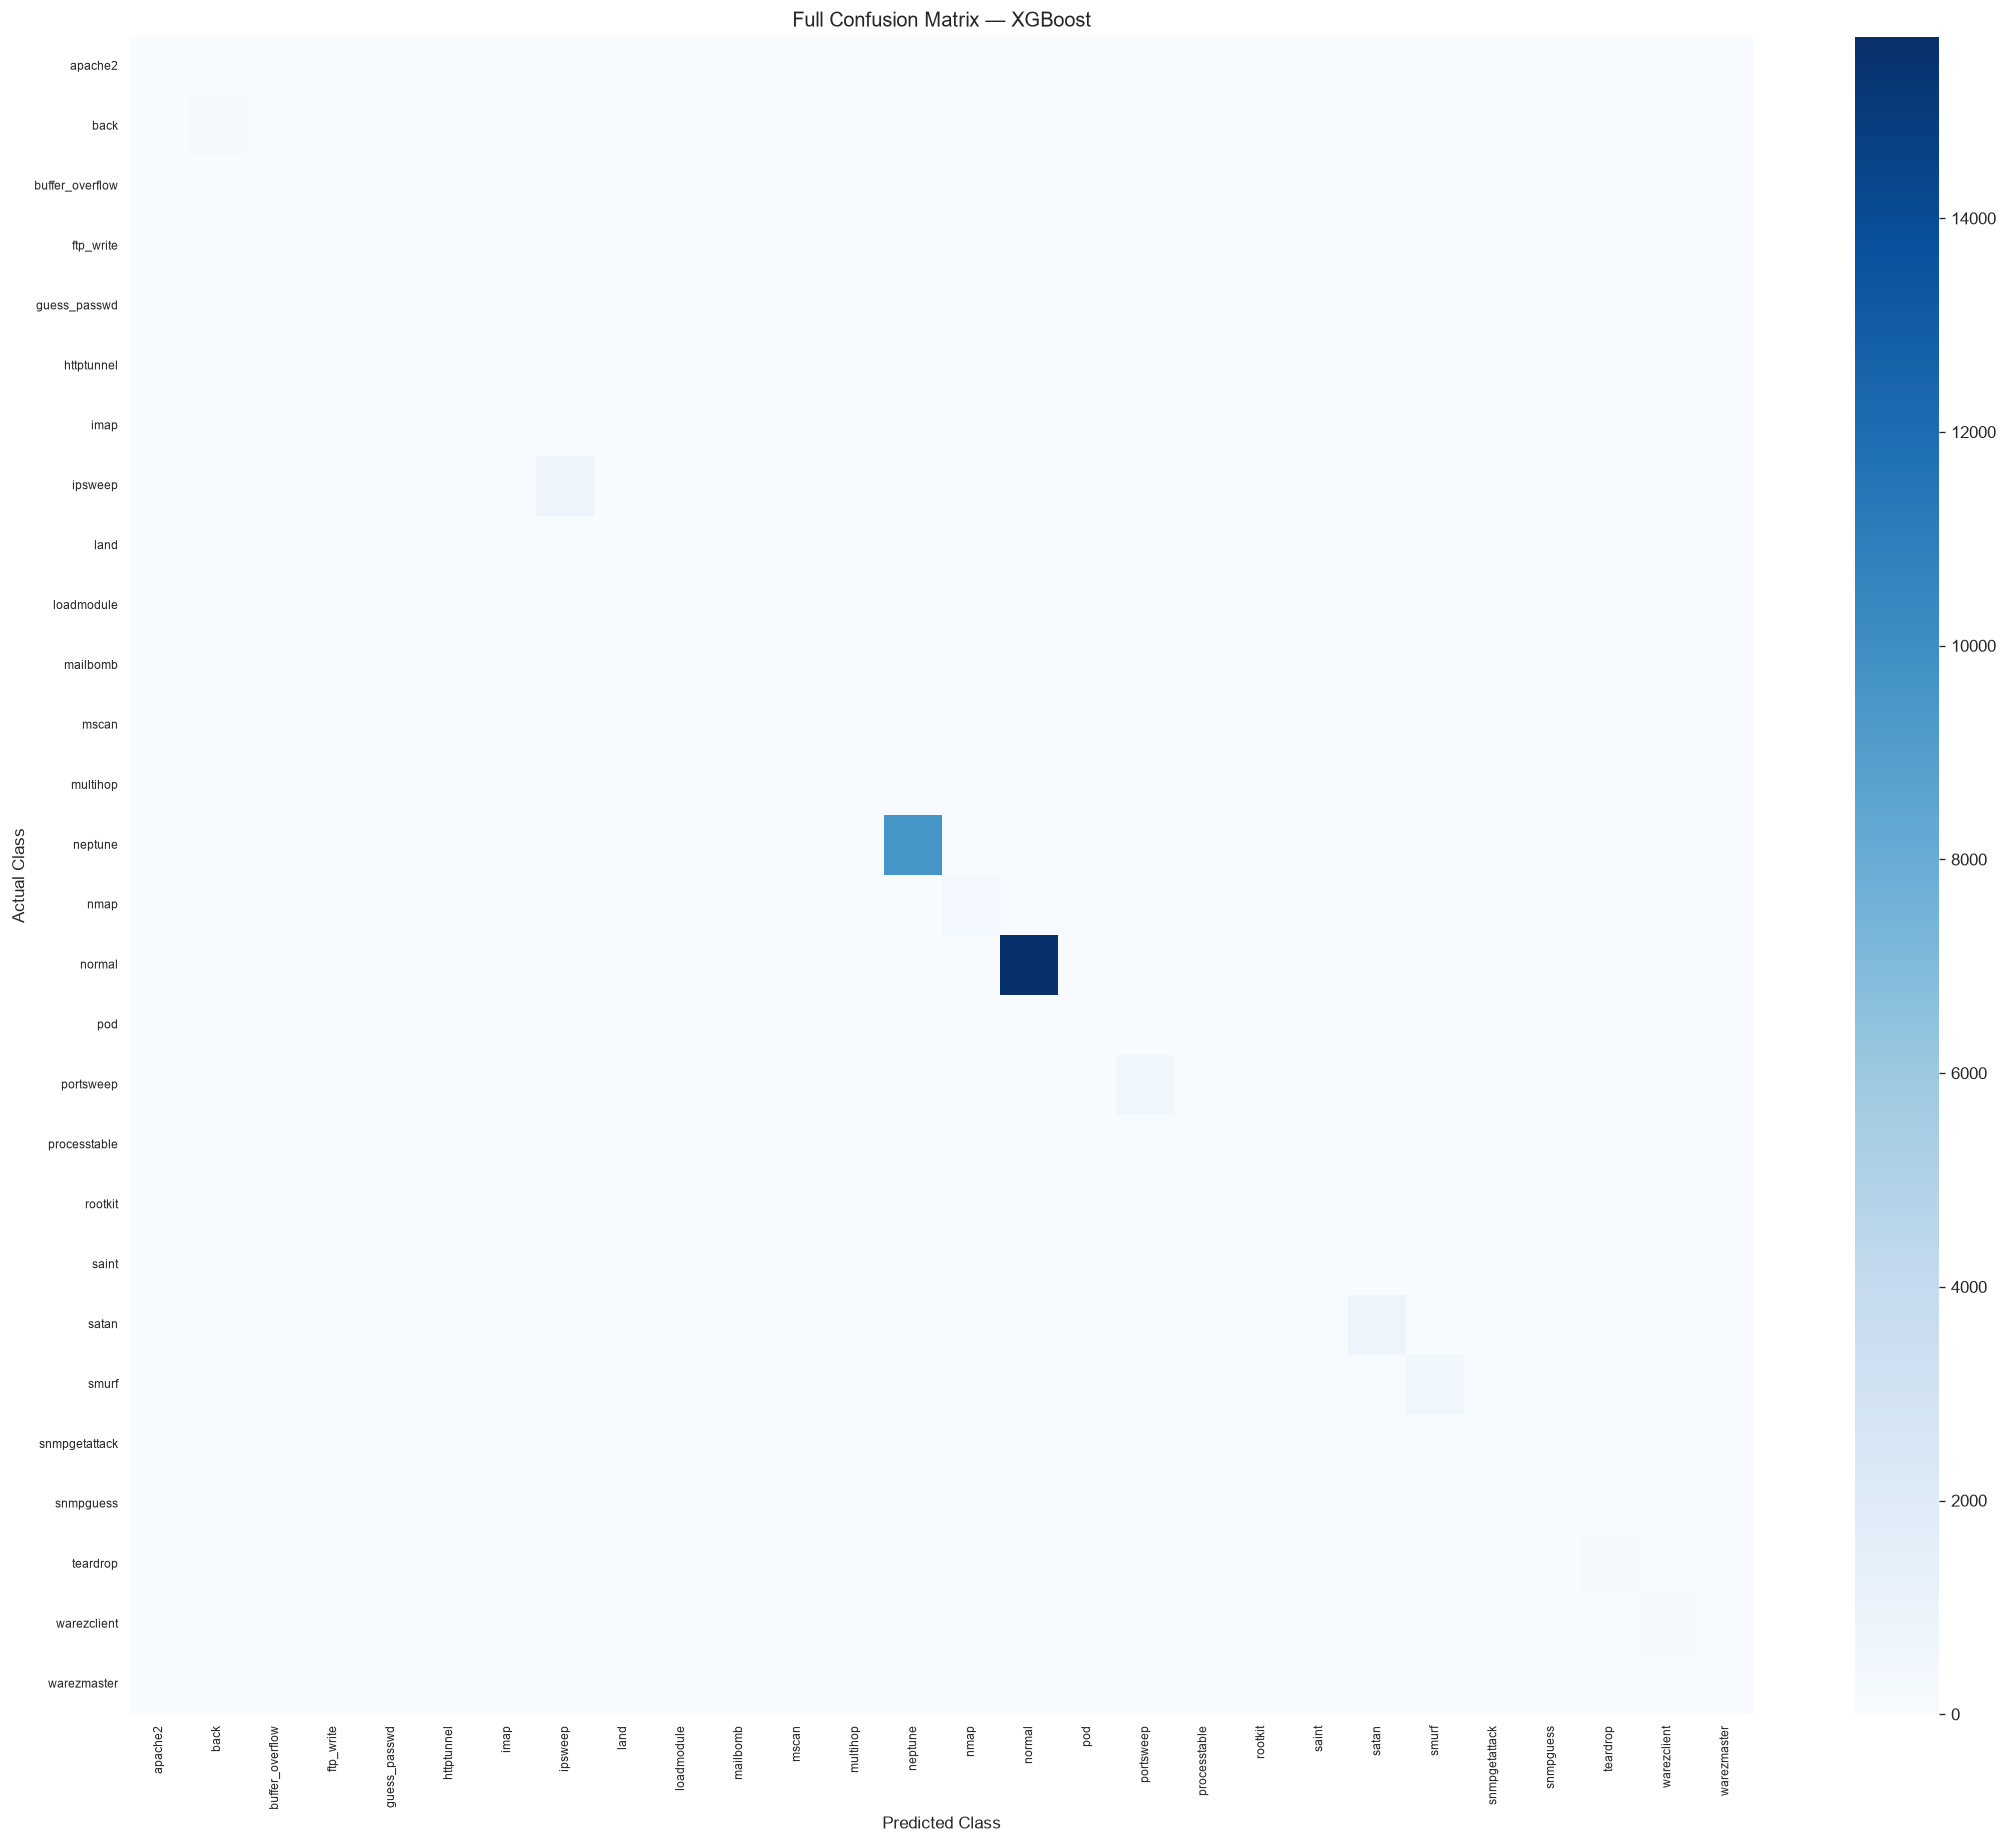

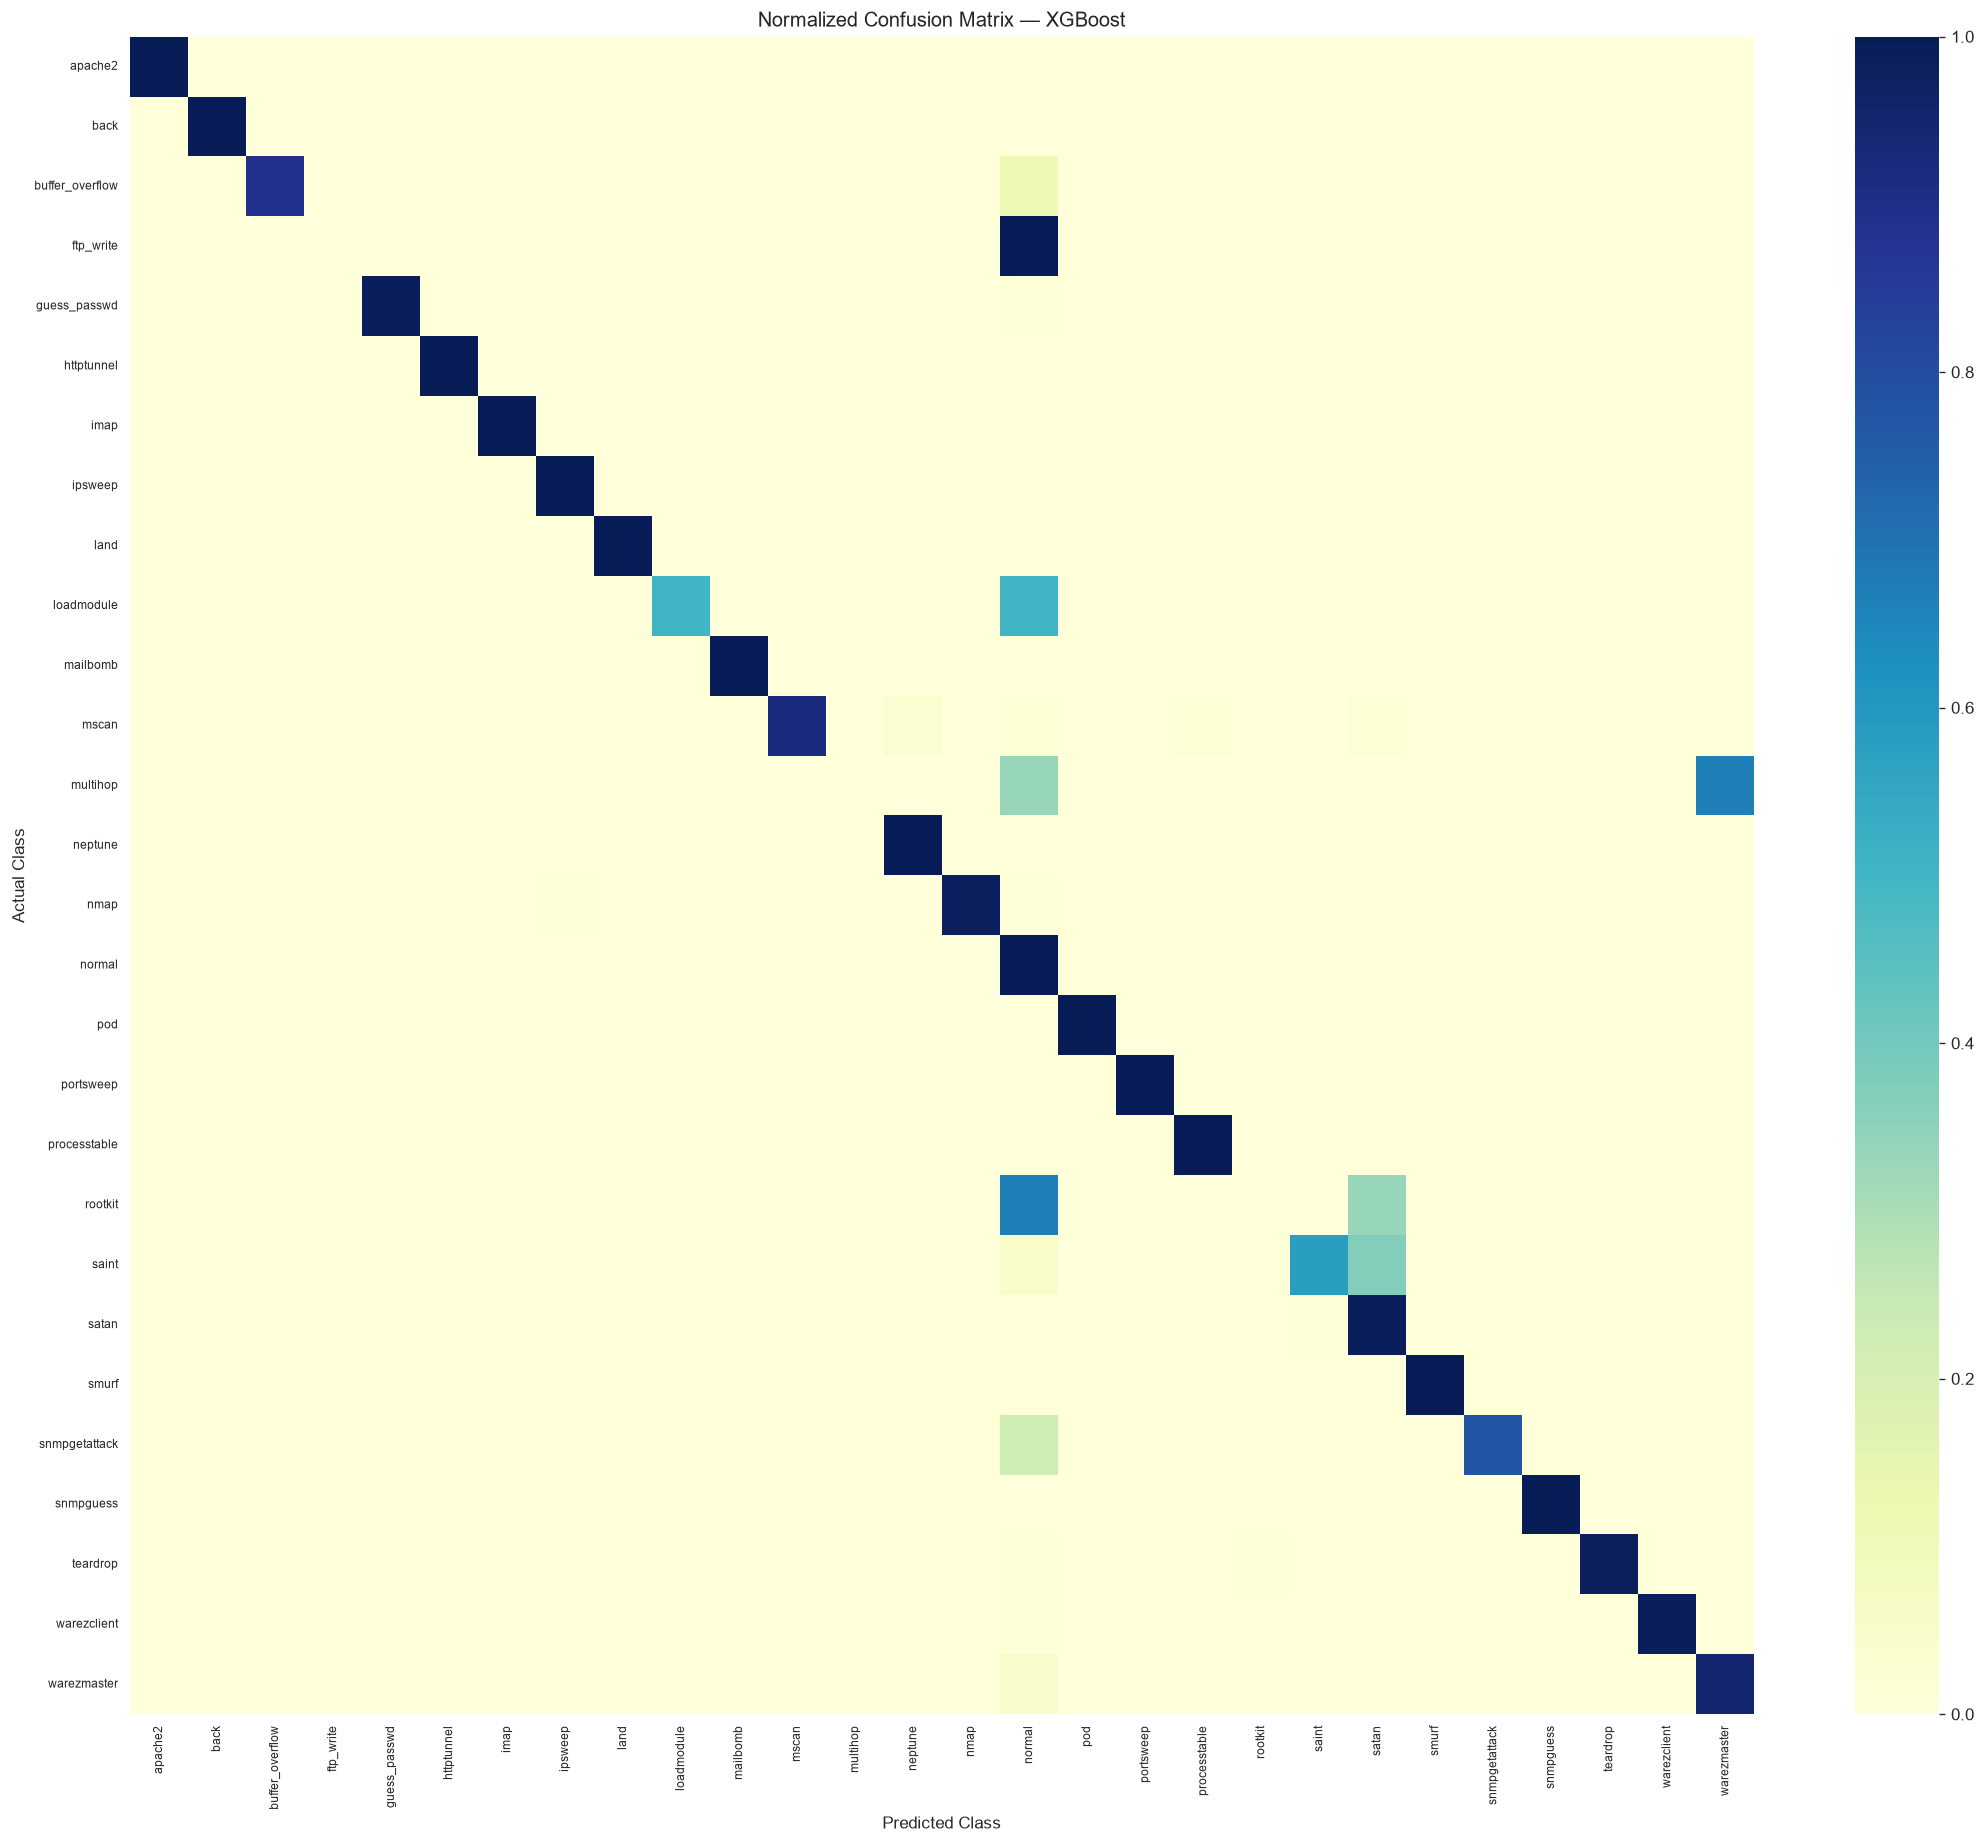

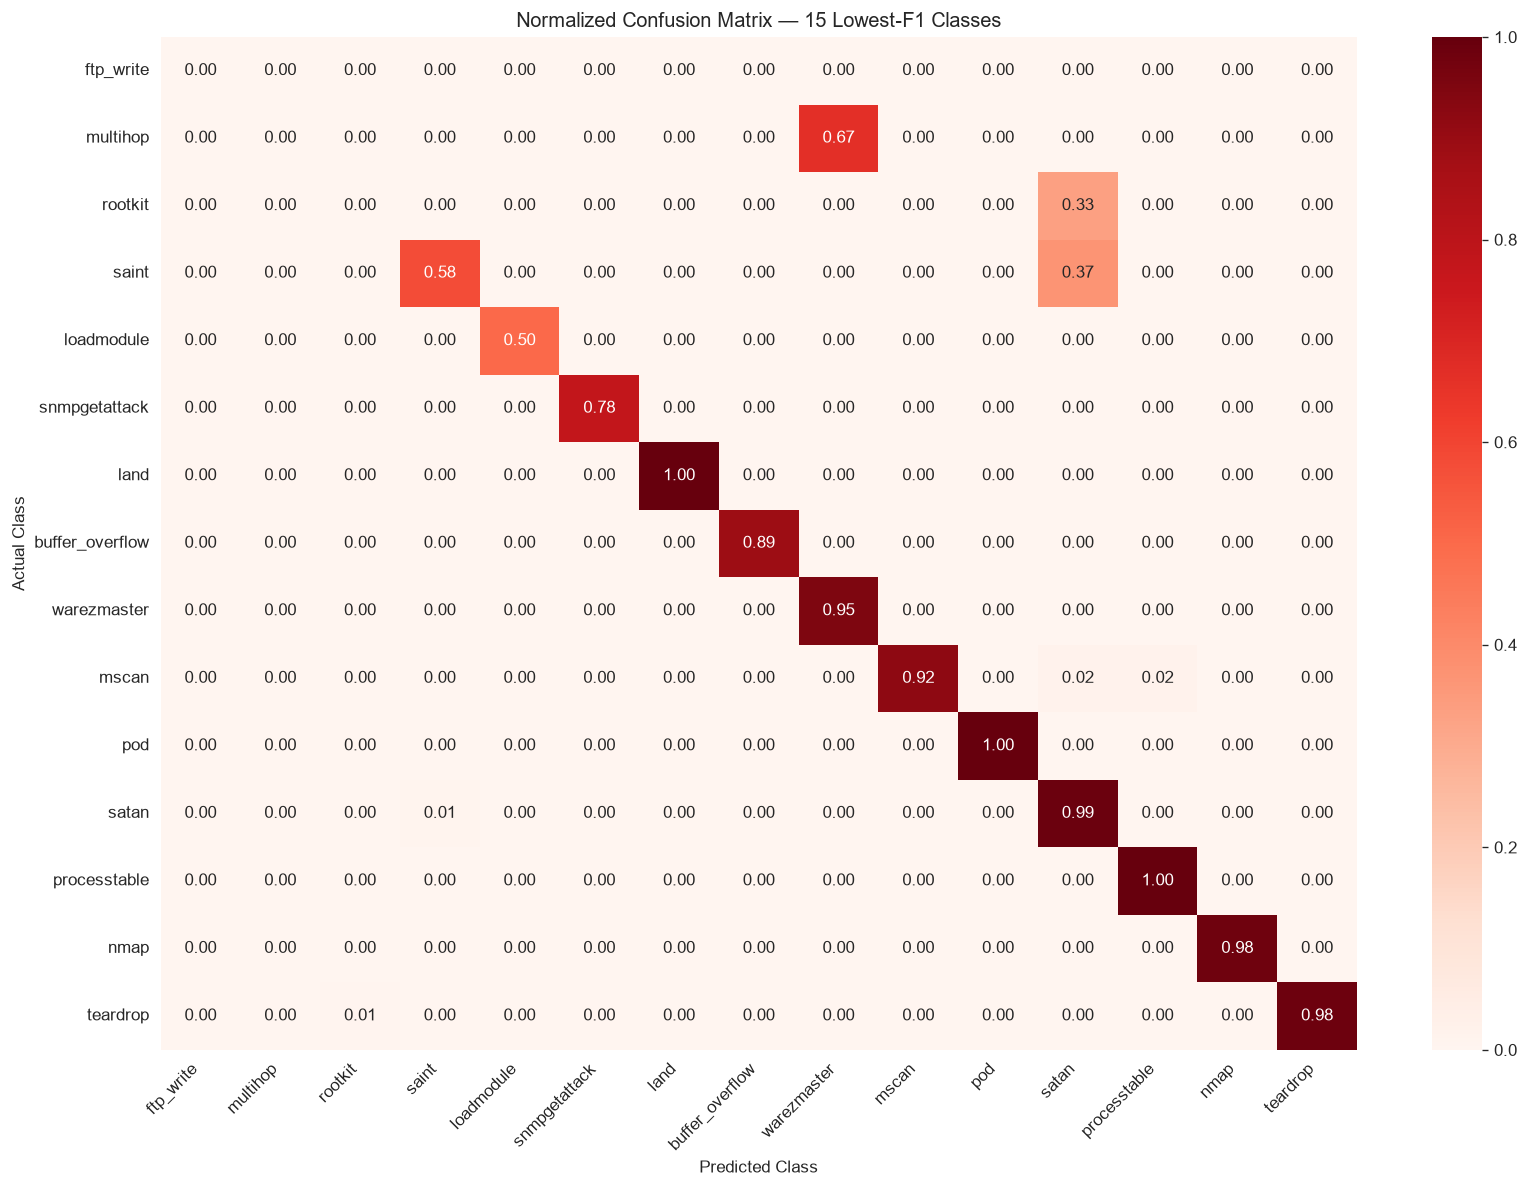


MISCLASSIFICATION SUMMARY
Misclassified samples : 73
Misclassification rate: 0.2458%

First 10 misclassified samples:


,Test_Index,Actual_ID,Predicted_ID,Confidence,Actual_Class,Predicted_Class
0,138,23,15,0.994405,snmpgetattack,normal
1,1404,23,15,0.984409,snmpgetattack,normal
2,1472,20,21,0.536465,saint,satan
3,2366,20,15,0.973529,saint,normal
4,2440,15,16,0.999910,normal,pod
5,2691,15,21,0.955553,normal,satan
6,3157,21,20,0.566022,satan,saint
7,3645,15,25,0.996638,normal,teardrop
8,3964,19,15,0.705272,rootkit,normal
9,4319,21,15,0.963732,satan,normal



Top 15 class-to-class errors:


,Actual_Class,Predicted_Class,Error_Count
0,saint,satan,7
1,satan,saint,7
2,normal,satan,4
3,normal,snmpgetattack,4
4,nmap,ipsweep,4
5,satan,normal,3
6,normal,pod,3
7,normal,land,3
8,warezmaster,normal,3
9,teardrop,normal,2



STEP 7.3 COMPLETED SUCCESSFULLY
Results saved in: D:\smart-cybersecurity-ml\results\phase7


In [4]:

# ============================================================
# PHASE 7 — STEP 7.3: CONFUSION MATRIX & MISCLASSIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. Prepare class labels and output paths
# ------------------------------------------------------------

class_ids = np.asarray(sorted(xgb_model.classes_.tolist()))

class_labels = [
    class_names[int(class_id)]
    for class_id in class_ids
]

# Rows = actual classes; columns = predicted classes
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_ids
)

# Row-normalized matrix: each value is the proportion of
# samples belonging to an actual class predicted as each class.
row_totals = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

# Save numeric matrices
pd.DataFrame(
    cm,
    index=class_labels,
    columns=class_labels
).to_csv(RESULTS_DIR / "phase7_confusion_matrix_full.csv")

pd.DataFrame(
    cm_normalized,
    index=class_labels,
    columns=class_labels
).to_csv(RESULTS_DIR / "phase7_confusion_matrix_normalized.csv")

print("=" * 75)
print("PHASE 7 — CONFUSION MATRIX ANALYSIS")
print("=" * 75)
print(f"Matrix shape          : {cm.shape}")
print(f"Total test samples    : {cm.sum():,}")
print(f"Correct predictions   : {np.trace(cm):,}")
print(f"Incorrect predictions : {cm.sum() - np.trace(cm):,}")

# ------------------------------------------------------------
# 2. Plot full confusion matrix
# ------------------------------------------------------------

fig_size = max(12, min(24, len(class_labels) * 0.65))

plt.figure(figsize=(fig_size, fig_size * 0.85))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
    cbar=True
)

plt.title("Full Confusion Matrix — XGBoost")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_confusion_matrix_full.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 3. Plot normalized confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(fig_size, fig_size * 0.85))

sns.heatmap(
    cm_normalized,
    cmap="YlGnBu",
    xticklabels=class_labels,
    yticklabels=class_labels,
    vmin=0,
    vmax=1,
    cbar=True
)

plt.title("Normalized Confusion Matrix — XGBoost")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_confusion_matrix_normalized.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 4. Identify the 15 classes with the lowest F1 scores
# ------------------------------------------------------------

# Uses the per-class results generated in Step 7.2.
top15_classes = (
    per_class_df
    .sort_values("F1_Score", ascending=True)
    .head(min(15, len(per_class_df)))["Class_ID"]
    .astype(int)
    .tolist()
)

top15_positions = [
    int(np.where(class_ids == class_id)[0][0])
    for class_id in top15_classes
]

top15_labels = [
    class_names[class_id]
    for class_id in top15_classes
]

# Select from the FULL row-normalized matrix.
# This preserves the actual per-class recall proportions;
# rows may sum to less than 1 after selecting only 15 columns.
cm_top15_normalized = cm_normalized[
    np.ix_(top15_positions, top15_positions)
]

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm_top15_normalized,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    xticklabels=top15_labels,
    yticklabels=top15_labels,
    vmin=0,
    vmax=1
)

plt.title("Normalized Confusion Matrix — 15 Lowest-F1 Classes")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_confusion_matrix_top15.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 5. Extract every misclassified test sample
# ------------------------------------------------------------

misclassified_mask = y_test != y_pred
misclassified_indices = np.flatnonzero(misclassified_mask)

misclassified_df = pd.DataFrame({
    "Test_Index": misclassified_indices,
    "Actual_ID": y_test[misclassified_mask].astype(int),
    "Predicted_ID": y_pred[misclassified_mask].astype(int),
    "Confidence": y_proba[misclassified_mask].max(axis=1)
})

misclassified_df["Actual_Class"] = misclassified_df[
    "Actual_ID"
].map(lambda class_id: class_names[int(class_id)])

misclassified_df["Predicted_Class"] = misclassified_df[
    "Predicted_ID"
].map(lambda class_id: class_names[int(class_id)])

misclassified_df.to_csv(
    RESULTS_DIR / "phase7_all_misclassified_samples.csv",
    index=False
)

print("\n" + "=" * 75)
print("MISCLASSIFICATION SUMMARY")
print("=" * 75)
print(f"Misclassified samples : {len(misclassified_df):,}")
print(
    f"Misclassification rate: "
    f"{misclassified_mask.mean():.4%}"
)

if not misclassified_df.empty:
    print("\nFirst 10 misclassified samples:")
    display(misclassified_df.head(10))

# ------------------------------------------------------------
# 6. Find the most frequent class-to-class errors
# ------------------------------------------------------------

error_records = []

for actual_position, actual_label in enumerate(class_labels):
    for predicted_position, predicted_label in enumerate(class_labels):
        if actual_position == predicted_position:
            continue

        error_count = int(cm[actual_position, predicted_position])

        if error_count > 0:
            error_records.append({
                "Actual_Class": actual_label,
                "Predicted_Class": predicted_label,
                "Error_Count": error_count
            })

error_patterns_df = pd.DataFrame(
    error_records,
    columns=["Actual_Class", "Predicted_Class", "Error_Count"]
)

if not error_patterns_df.empty:
    error_patterns_df = error_patterns_df.sort_values(
        "Error_Count",
        ascending=False
    ).reset_index(drop=True)

error_patterns_df.to_csv(
    RESULTS_DIR / "phase7_misclassification_patterns.csv",
    index=False
)

print("\nTop 15 class-to-class errors:")
if not error_patterns_df.empty:
    display(error_patterns_df.head(15))
else:
    print("No misclassified samples found.")

print("\n" + "=" * 75)
print("STEP 7.3 COMPLETED SUCCESSFULLY")
print("=" * 75)
print(f"Results saved in: {RESULTS_DIR}")


Phase 7 — Step 7.4: Multiclass ROC Curves and AUC Analysis

PHASE 7 — PER-CLASS ROC-AUC RESULTS


,Class_ID,Attack_Class,Positive_Samples,Negative_Samples,AUC,Status
12,12,multihop,3,29693,0.9506,Calculated
19,19,rootkit,3,29693,0.9952,Calculated
20,20,saint,19,29677,0.9992,Calculated
3,3,ftp_write,2,29694,0.9993,Calculated
23,23,snmpgetattack,9,29687,0.9996,Calculated
16,16,pod,47,29649,0.9999,Calculated
15,15,normal,15718,13978,0.9999,Calculated
8,8,land,4,29692,0.9999,Calculated
9,9,loadmodule,2,29694,0.9999,Calculated
27,27,warezmaster,60,29636,1.0000,Calculated



Macro ROC-AUC (valid classes): 0.997982
Weighted ROC-AUC (valid classes): 0.999959


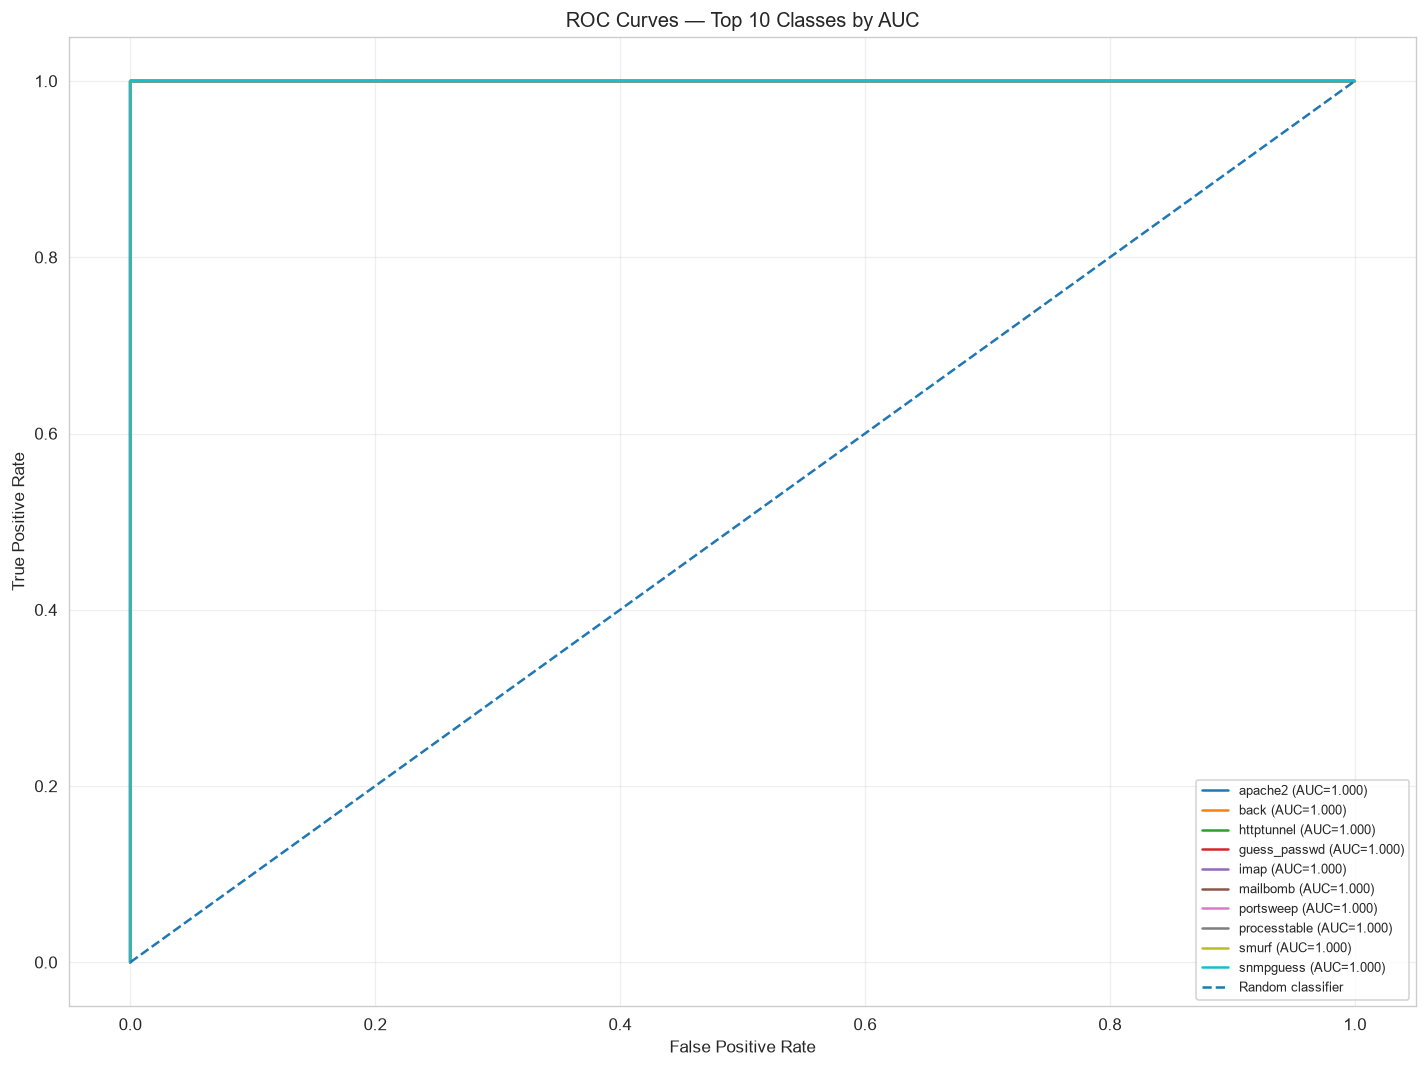

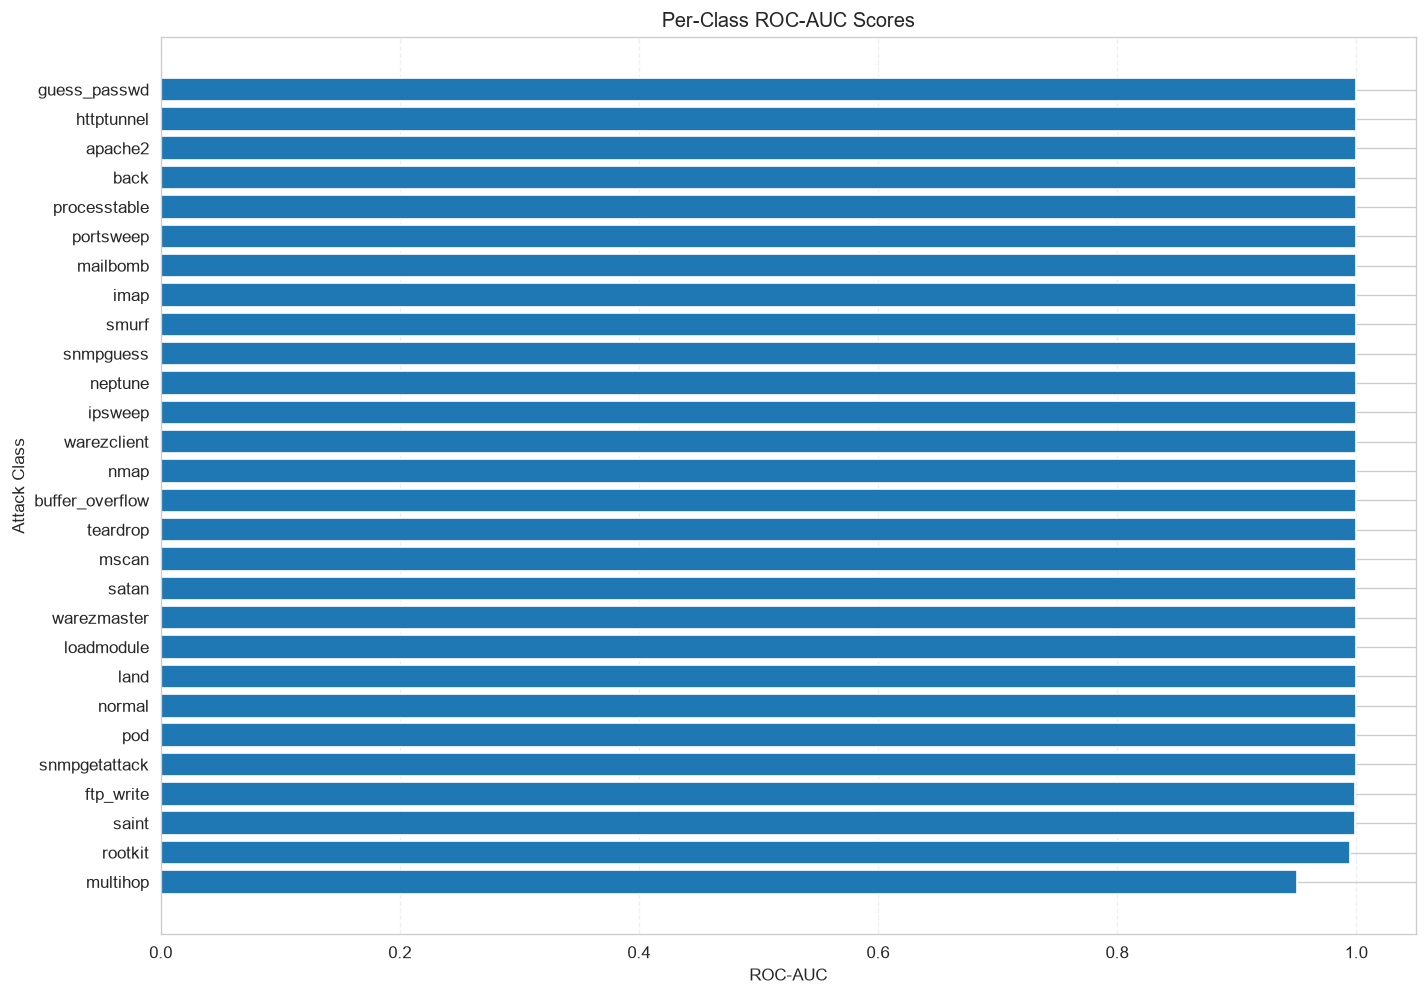


STEP 7.4 COMPLETED SUCCESSFULLY
ROC results saved in: D:\smart-cybersecurity-ml\results\phase7


In [5]:

# ============================================================
# PHASE 7 — STEP 7.4: MULTICLASS ROC CURVES & AUC ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# ------------------------------------------------------------
# 1. Prepare labels and probabilities
# ------------------------------------------------------------

class_ids = np.asarray(sorted(xgb_model.classes_.tolist()))

y_proba_roc = np.asarray(y_proba_aligned)

y_test_bin = label_binarize(
    y_test,
    classes=class_ids
)

if y_test_bin.shape[1] != y_proba_roc.shape[1]:
    raise ValueError(
        "Binarized test labels and probability columns do not match."
    )

roc_results = []
valid_curves = {}

# ------------------------------------------------------------
# 2. Calculate ROC curve and AUC for each class
# ------------------------------------------------------------

for i, class_id in enumerate(class_ids):

    class_name = class_names[int(class_id)]
    y_true_class = y_test_bin[:, i]
    y_score_class = y_proba_roc[:, i]

    positive_count = int(y_true_class.sum())
    negative_count = int(len(y_true_class) - positive_count)

    # ROC requires both positive and negative examples.
    if positive_count == 0 or negative_count == 0:
        roc_results.append({
            "Class_ID": int(class_id),
            "Attack_Class": class_name,
            "Positive_Samples": positive_count,
            "Negative_Samples": negative_count,
            "AUC": np.nan,
            "Status": "Skipped: class lacks positive or negative samples"
        })
        continue

    fpr, tpr, thresholds = roc_curve(
        y_true_class,
        y_score_class
    )

    auc_value = auc(fpr, tpr)

    valid_curves[int(class_id)] = {
        "name": class_name,
        "fpr": fpr,
        "tpr": tpr,
        "auc": auc_value
    }

    roc_results.append({
        "Class_ID": int(class_id),
        "Attack_Class": class_name,
        "Positive_Samples": positive_count,
        "Negative_Samples": negative_count,
        "AUC": float(auc_value),
        "Status": "Calculated"
    })

roc_df = pd.DataFrame(roc_results)

roc_df.to_csv(
    RESULTS_DIR / "phase7_roc_auc_per_class.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Display AUC results
# ------------------------------------------------------------

print("=" * 75)
print("PHASE 7 — PER-CLASS ROC-AUC RESULTS")
print("=" * 75)

display(
    roc_df.sort_values(
        "AUC",
        ascending=True,
        na_position="first"
    ).style.format({
        "AUC": "{:.4f}"
    }, na_rep="N/A")
)

# ------------------------------------------------------------
# 4. Calculate macro and weighted ROC-AUC
# ------------------------------------------------------------

valid_class_ids = [
    class_id
    for class_id in class_ids
    if int(class_id) in valid_curves
]

if valid_class_ids:
    valid_positions = [
        int(np.where(class_ids == class_id)[0][0])
        for class_id in valid_class_ids
    ]

    y_true_valid = y_test_bin[:, valid_positions]
    y_score_valid = y_proba_roc[:, valid_positions]

    # Each retained class has positive and negative examples.
    macro_auc = roc_auc_score(
        y_true_valid,
        y_score_valid,
        average="macro"
    )

    weighted_auc = roc_auc_score(
        y_true_valid,
        y_score_valid,
        average="weighted"
    )
else:
    macro_auc = np.nan
    weighted_auc = np.nan

print("\nMacro ROC-AUC (valid classes):", f"{macro_auc:.6f}")
print("Weighted ROC-AUC (valid classes):", f"{weighted_auc:.6f}")

# ------------------------------------------------------------
# 5. Plot ROC curves for the 10 highest-AUC classes
# ------------------------------------------------------------

valid_auc_df = roc_df.dropna(subset=["AUC"]).sort_values(
    "AUC",
    ascending=False
)

top10_class_ids = (
    valid_auc_df.head(10)["Class_ID"].astype(int).tolist()
)

plt.figure(figsize=(12, 9))

for class_id in top10_class_ids:
    curve = valid_curves[class_id]

    plt.plot(
        curve["fpr"],
        curve["tpr"],
        label=f'{curve["name"]} (AUC={curve["auc"]:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Top 10 Classes by AUC")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_roc_curves_top10.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 6. Plot AUC scores for all classes
# ------------------------------------------------------------

plot_auc_df = valid_auc_df.sort_values("AUC", ascending=True)

plt.figure(figsize=(12, max(7, len(plot_auc_df) * 0.30)))

plt.barh(
    plot_auc_df["Attack_Class"],
    plot_auc_df["AUC"]
)

plt.xlabel("ROC-AUC")
plt.ylabel("Attack Class")
plt.title("Per-Class ROC-AUC Scores")
plt.xlim(0, 1.05)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_roc_auc_all_classes.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 7. Save ROC summary
# ------------------------------------------------------------

roc_summary = {
    "model": type(xgb_model).__name__,
    "valid_class_count": int(len(valid_curves)),
    "skipped_class_count": int(len(class_ids) - len(valid_curves)),
    "macro_auc_valid_classes": (
        float(macro_auc) if np.isfinite(macro_auc) else None
    ),
    "weighted_auc_valid_classes": (
        float(weighted_auc) if np.isfinite(weighted_auc) else None
    )
}

import json

with open(
    RESULTS_DIR / "phase7_roc_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(roc_summary, file, indent=4)

print("\n" + "=" * 75)
print("STEP 7.4 COMPLETED SUCCESSFULLY")
print("=" * 75)
print(f"ROC results saved in: {RESULTS_DIR}")


Phase 7 — Step 7.5: Precision-Recall Curves and Average Precision (AP)

PHASE 7 — PER-CLASS AVERAGE PRECISION


,Class_ID,Attack_Class,Positive_Samples,Negative_Samples,Average_Precision,Status
19,19,rootkit,3,29693,0.0146,Calculated
12,12,multihop,3,29693,0.0674,Calculated
3,3,ftp_write,2,29694,0.1244,Calculated
23,23,snmpgetattack,9,29687,0.4978,Calculated
8,8,land,4,29692,0.5595,Calculated
9,9,loadmodule,2,29694,0.7000,Calculated
20,20,saint,19,29677,0.7228,Calculated
16,16,pod,47,29649,0.8995,Calculated
27,27,warezmaster,60,29636,0.9867,Calculated
2,2,buffer_overflow,9,29687,0.9889,Calculated



Macro Average Precision: 0.841254
Weighted Average Precision: 0.999081


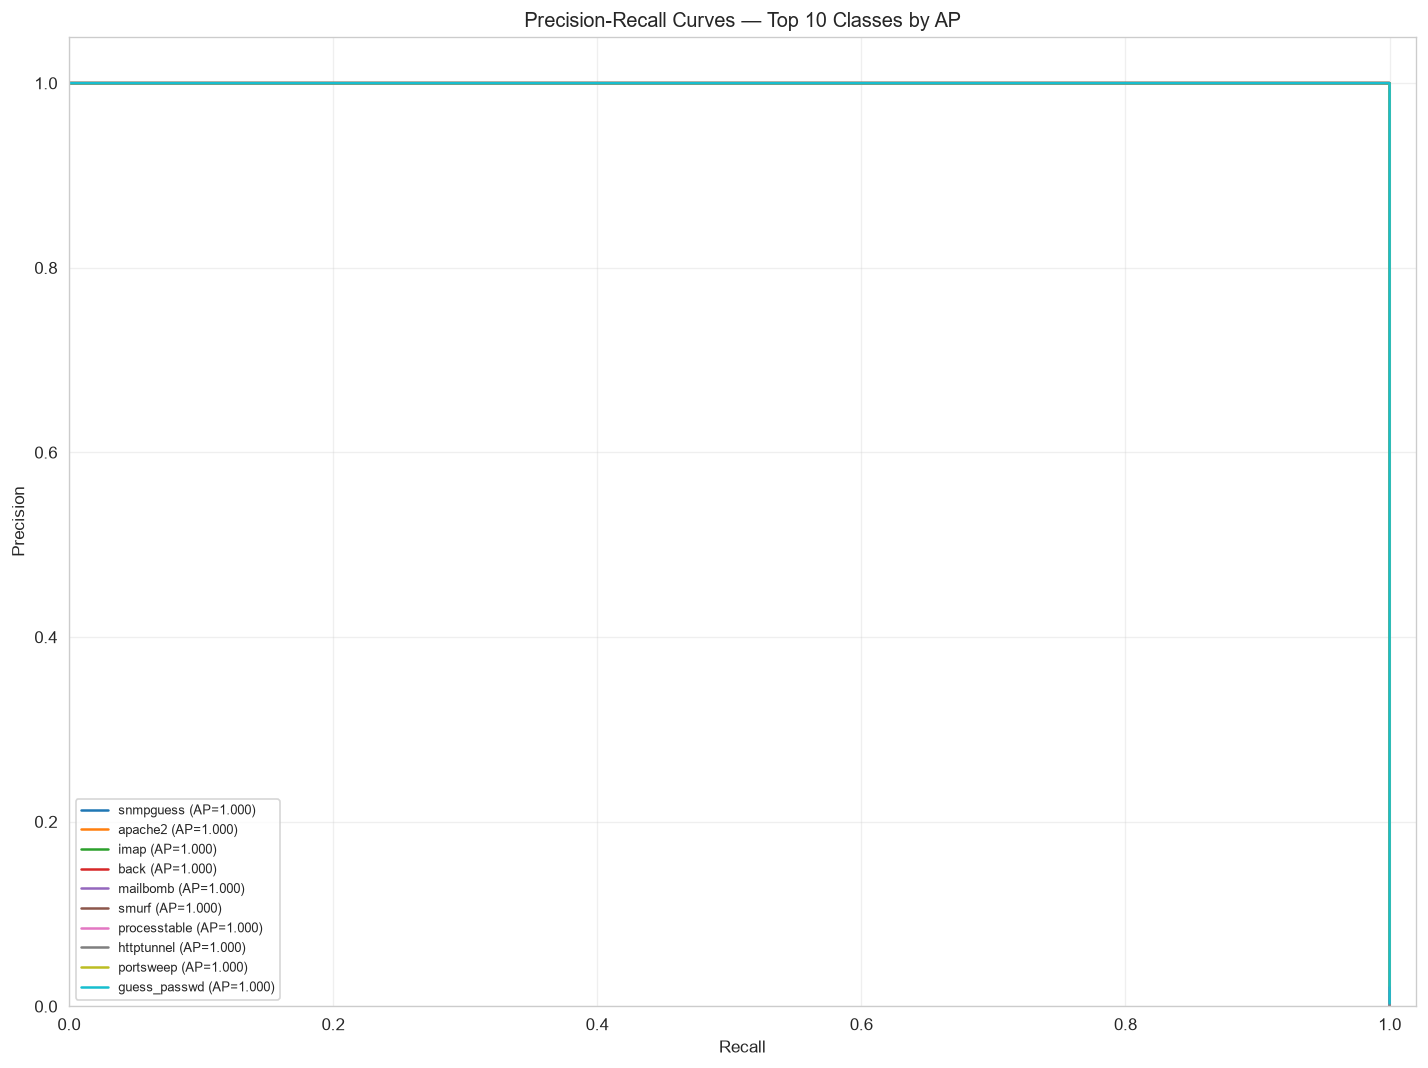

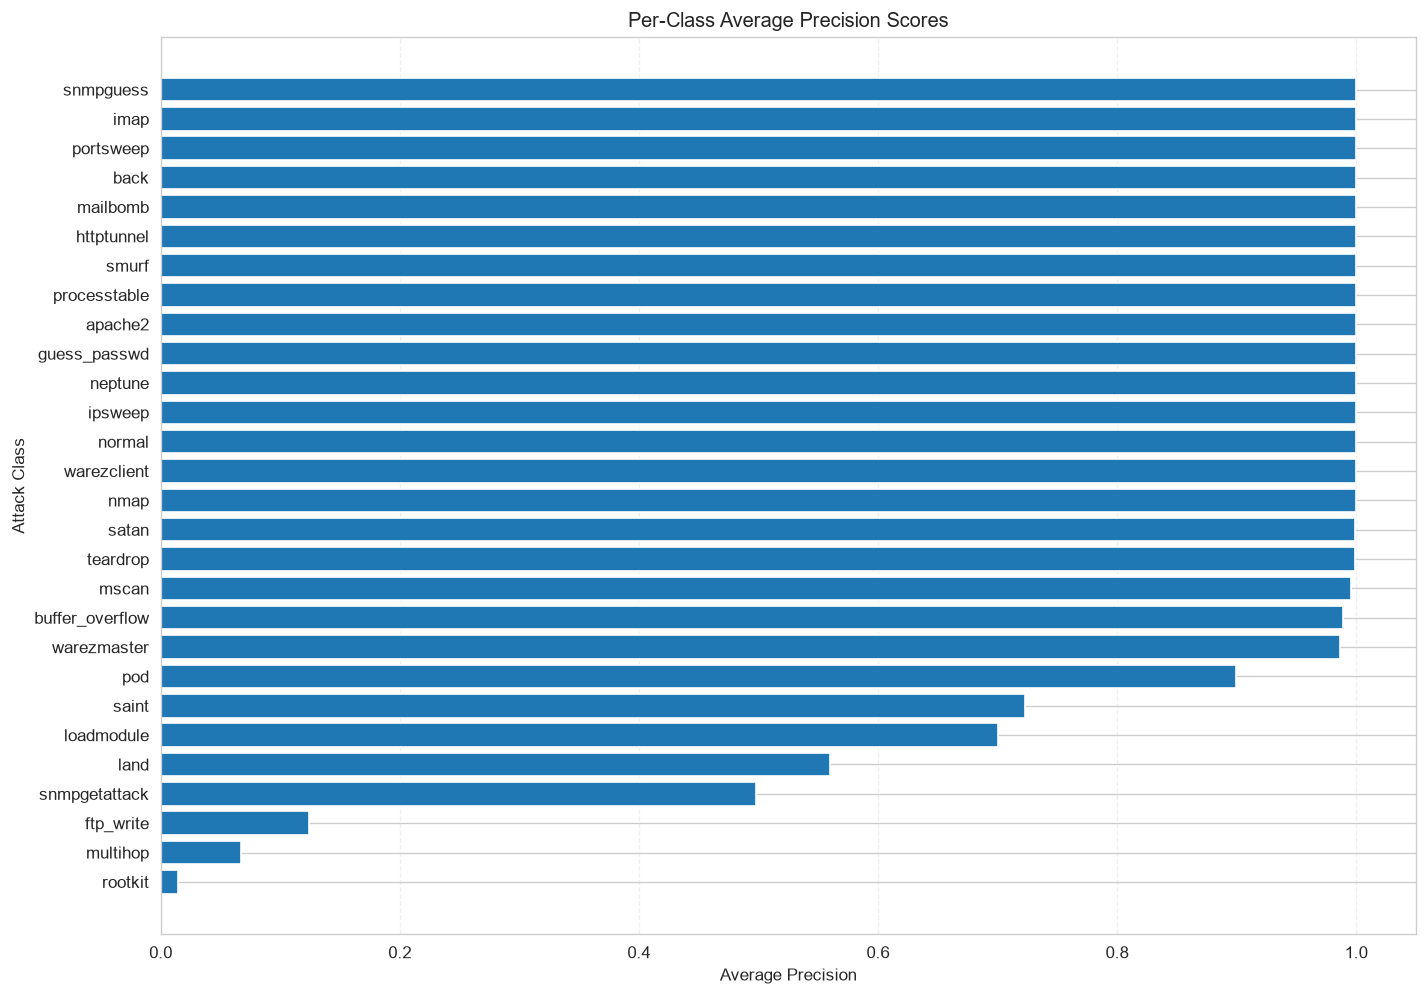


STEP 7.5 COMPLETED SUCCESSFULLY
Results saved in: D:\smart-cybersecurity-ml\results\phase7


In [7]:

# ============================================================
# PHASE 7 — STEP 7.5: PRECISION-RECALL CURVES & AVERAGE PRECISION
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score

# ------------------------------------------------------------
# 1. Prepare labels and predicted probabilities
# ------------------------------------------------------------

class_ids = np.asarray(sorted(xgb_model.classes_.tolist()))
y_proba_pr = np.asarray(y_proba_aligned)

y_test_bin = label_binarize(
    y_test,
    classes=class_ids
)

if y_test_bin.shape[1] != y_proba_pr.shape[1]:
    raise ValueError(
        "Binarized test labels and probability columns do not match."
    )

pr_results = []
valid_pr_curves = {}

# ------------------------------------------------------------
# 2. Calculate precision, recall and AP for each class
# ------------------------------------------------------------

for i, class_id in enumerate(class_ids):

    class_name = class_names[int(class_id)]
    y_true_class = y_test_bin[:, i]
    y_score_class = y_proba_pr[:, i]

    positive_count = int(y_true_class.sum())
    negative_count = int(len(y_true_class) - positive_count)

    # AP needs positive examples. Skip classes absent from test data.
    if positive_count == 0:
        pr_results.append({
            "Class_ID": int(class_id),
            "Attack_Class": class_name,
            "Positive_Samples": positive_count,
            "Negative_Samples": negative_count,
            "Average_Precision": np.nan,
            "Status": "Skipped: no positive test samples"
        })
        continue

    precision, recall, thresholds = precision_recall_curve(
        y_true_class,
        y_score_class
    )

    ap_value = average_precision_score(
        y_true_class,
        y_score_class
    )

    valid_pr_curves[int(class_id)] = {
        "name": class_name,
        "precision": precision,
        "recall": recall,
        "ap": ap_value
    }

    pr_results.append({
        "Class_ID": int(class_id),
        "Attack_Class": class_name,
        "Positive_Samples": positive_count,
        "Negative_Samples": negative_count,
        "Average_Precision": float(ap_value),
        "Status": "Calculated"
    })

pr_df = pd.DataFrame(pr_results)

pr_df.to_csv(
    RESULTS_DIR / "phase7_precision_recall_per_class.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Display per-class Average Precision
# ------------------------------------------------------------

print("=" * 75)
print("PHASE 7 — PER-CLASS AVERAGE PRECISION")
print("=" * 75)

display(
    pr_df.sort_values(
        "Average_Precision",
        ascending=True,
        na_position="first"
    ).style.format({
        "Average_Precision": "{:.4f}"
    }, na_rep="N/A")
)

# ------------------------------------------------------------
# 4. Calculate macro and weighted Average Precision
# ------------------------------------------------------------

valid_class_ids = [
    class_id
    for class_id in class_ids
    if int(class_id) in valid_pr_curves
]

if valid_class_ids:
    valid_positions = [
        int(np.where(class_ids == class_id)[0][0])
        for class_id in valid_class_ids
    ]

    y_true_valid = y_test_bin[:, valid_positions]
    y_score_valid = y_proba_pr[:, valid_positions]

    # Each retained class has at least one positive test sample.
    macro_ap = average_precision_score(
        y_true_valid,
        y_score_valid,
        average="macro"
    )

    weighted_ap = average_precision_score(
        y_true_valid,
        y_score_valid,
        average="weighted"
    )
else:
    macro_ap = np.nan
    weighted_ap = np.nan

print("\nMacro Average Precision:", f"{macro_ap:.6f}")
print("Weighted Average Precision:", f"{weighted_ap:.6f}")

# ------------------------------------------------------------
# 5. Plot PR curves for the 10 highest-AP classes
# ------------------------------------------------------------

valid_ap_df = pr_df.dropna(
    subset=["Average_Precision"]
).sort_values(
    "Average_Precision",
    ascending=False
)

top10_class_ids = (
    valid_ap_df.head(10)["Class_ID"].astype(int).tolist()
)

plt.figure(figsize=(12, 9))

for class_id in top10_class_ids:
    curve = valid_pr_curves[class_id]

    plt.plot(
        curve["recall"],
        curve["precision"],
        label=f'{curve["name"]} (AP={curve["ap"]:.3f})'
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — Top 10 Classes by AP")
plt.xlim(0, 1.02)
plt.ylim(0, 1.05)
plt.legend(loc="lower left", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_pr_curves_top10.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 6. Plot AP scores for all classes
# ------------------------------------------------------------

plot_ap_df = valid_ap_df.sort_values(
    "Average_Precision",
    ascending=True
)

plt.figure(figsize=(12, max(7, len(plot_ap_df) * 0.30)))

plt.barh(
    plot_ap_df["Attack_Class"],
    plot_ap_df["Average_Precision"]
)

plt.xlabel("Average Precision")
plt.ylabel("Attack Class")
plt.title("Per-Class Average Precision Scores")
plt.xlim(0, 1.05)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_average_precision_all_classes.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 7. Save the summary
# ------------------------------------------------------------

pr_summary = {
    "model": type(xgb_model).__name__,
    "valid_class_count": int(len(valid_pr_curves)),
    "skipped_class_count": int(
        len(class_ids) - len(valid_pr_curves)
    ),
    "macro_average_precision": (
        float(macro_ap) if np.isfinite(macro_ap) else None
    ),
    "weighted_average_precision": (
        float(weighted_ap) if np.isfinite(weighted_ap) else None
    )
}

with open(
    RESULTS_DIR / "phase7_pr_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(pr_summary, file, indent=4)

print("\n" + "=" * 75)
print("STEP 7.5 COMPLETED SUCCESSFULLY")
print("=" * 75)
print(f"Results saved in: {RESULTS_DIR}")

Phase 7 — Step 7.6: Per-Class F1 Analysis and Performance Categories

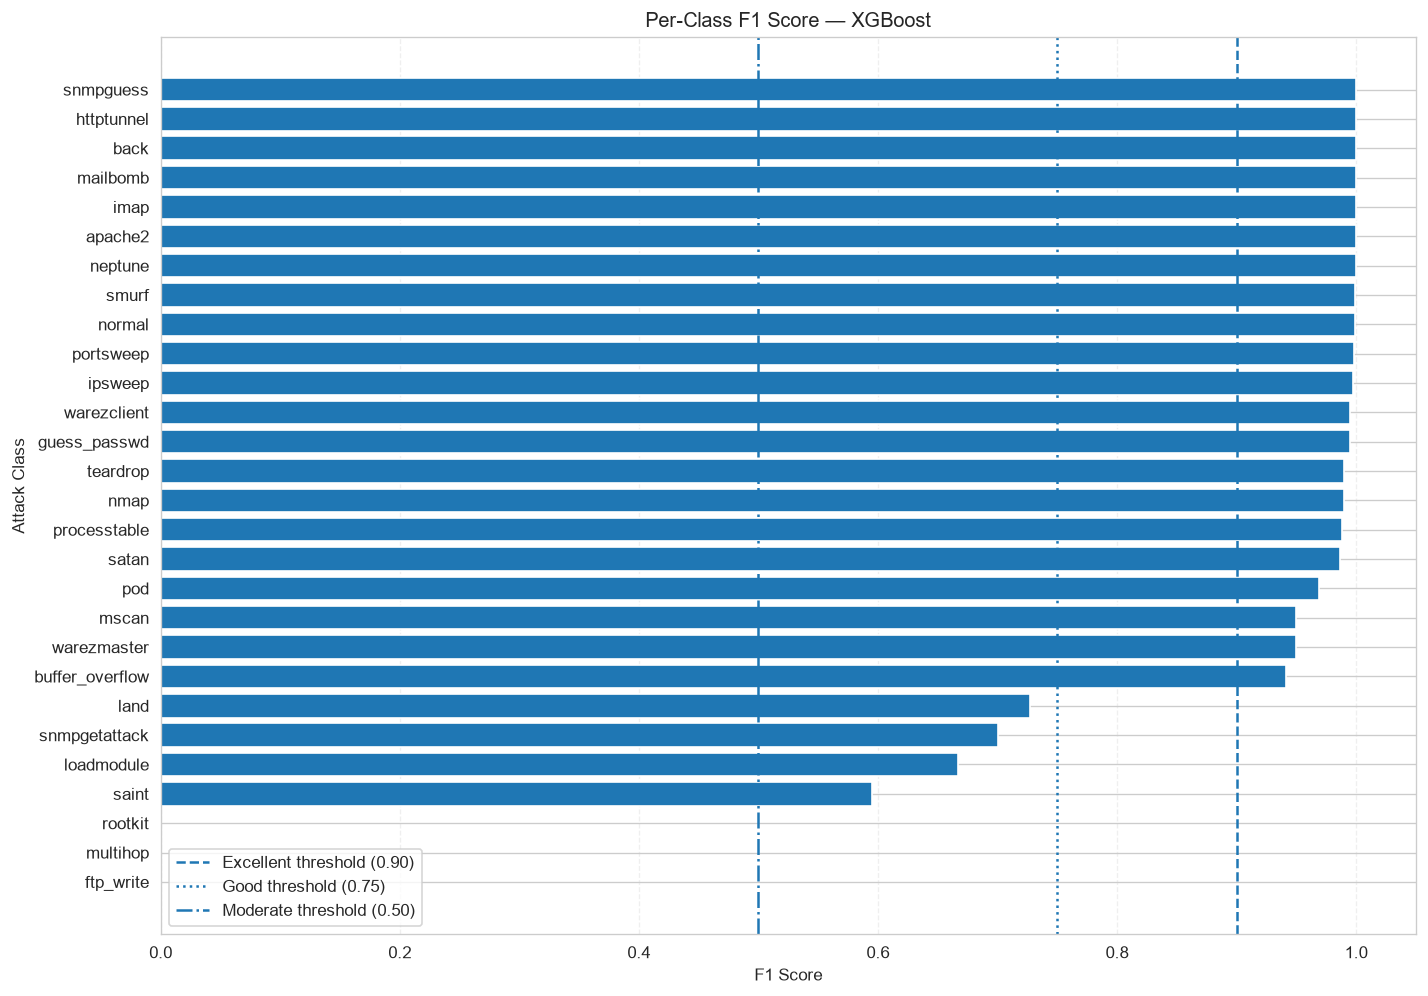

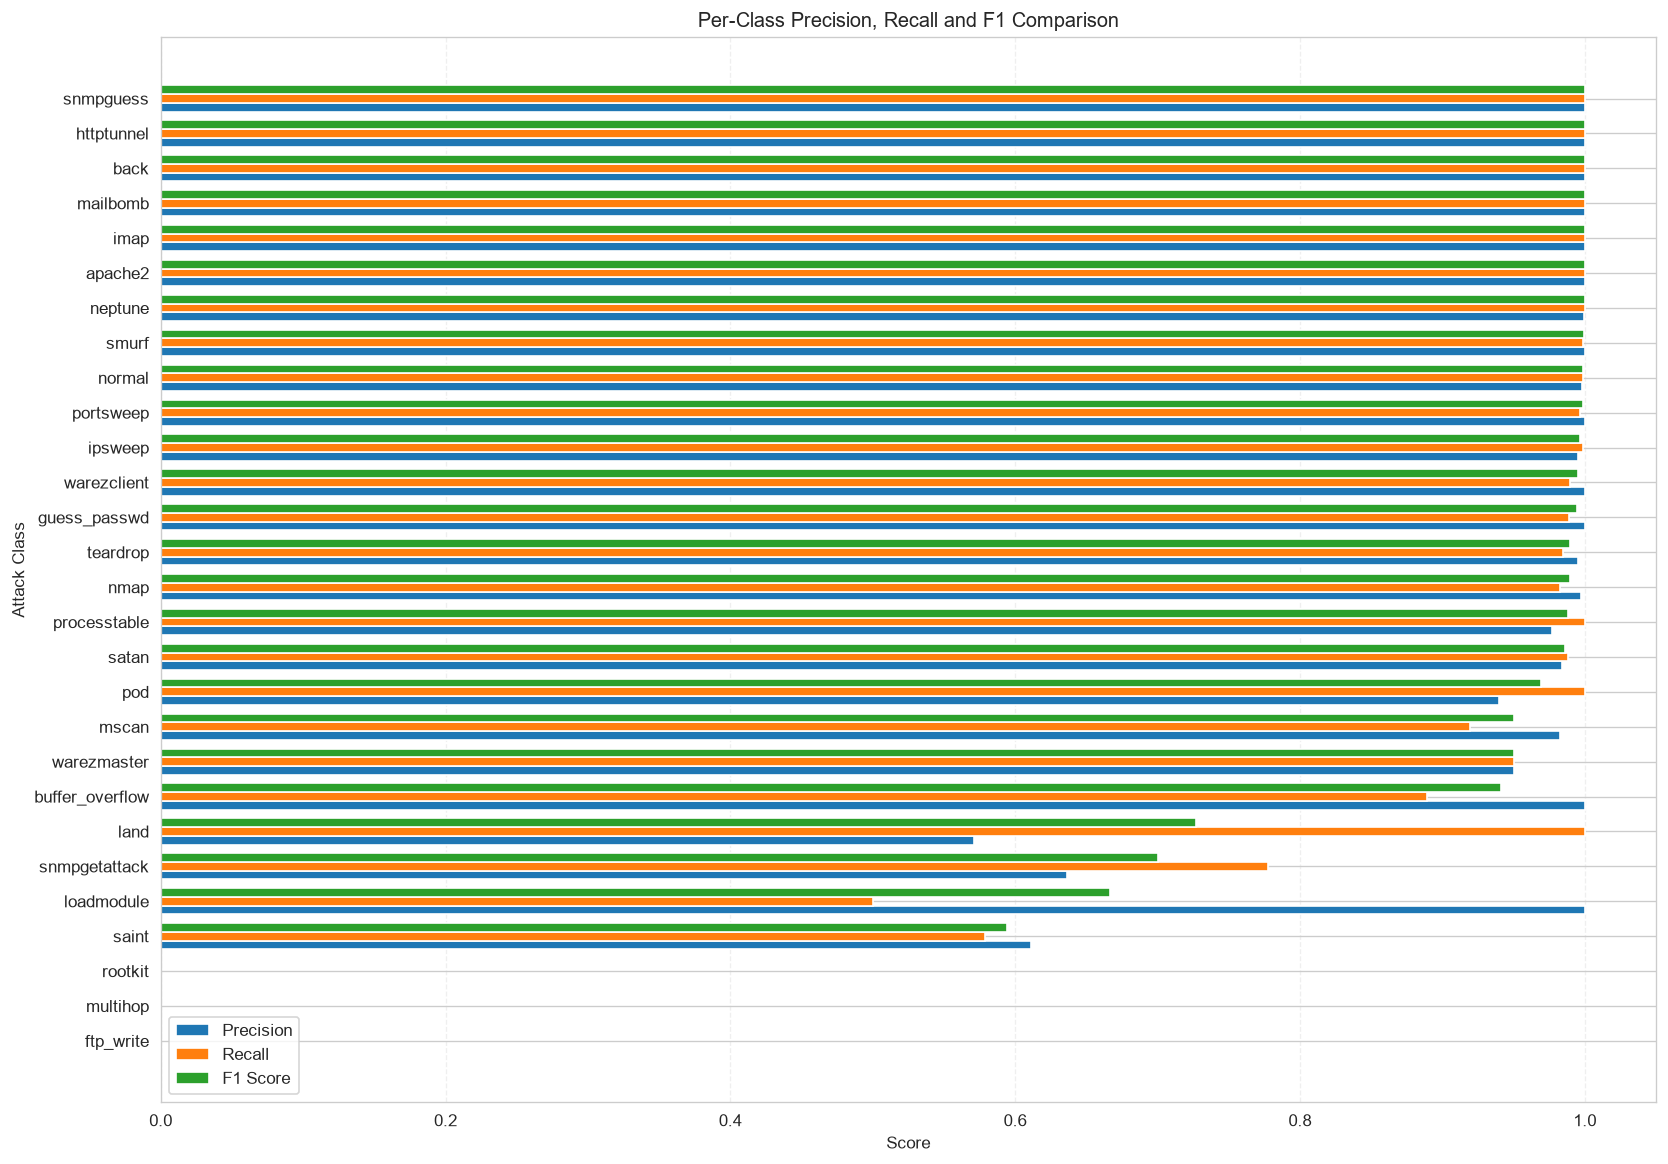

PHASE 7 — PERFORMANCE CATEGORY SUMMARY


,Performance_Category,Number_of_Classes
0,Excellent,21
1,Good,0
2,Moderate,4
3,Poor,3


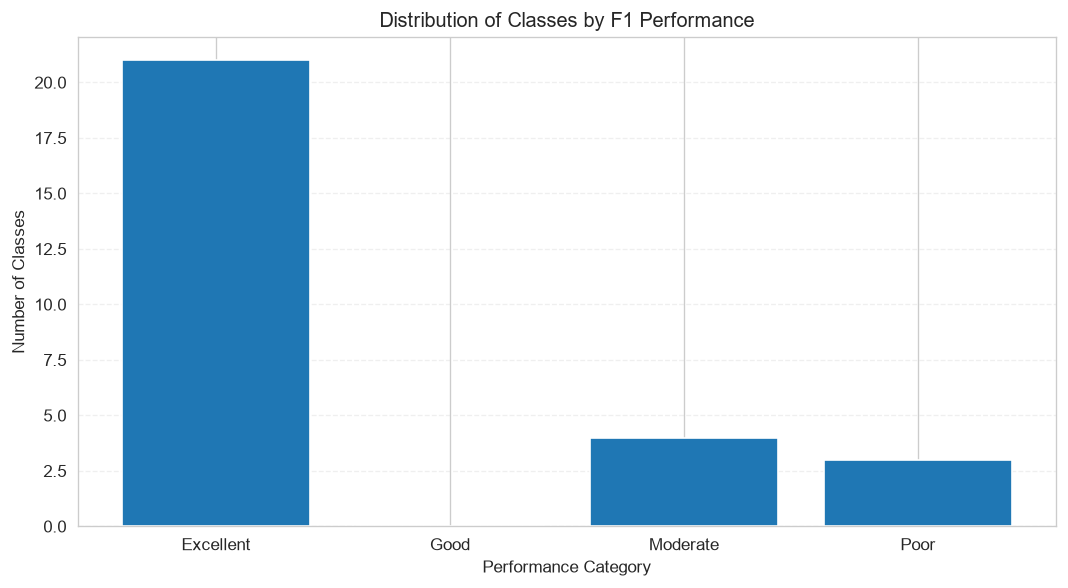


10 WEAKEST CLASSES BY F1 SCORE


,Attack_Class,Precision,Recall,F1_Score,Support
0,ftp_write,0.0000,0.0000,0.0000,2
1,multihop,0.0000,0.0000,0.0000,3
2,rootkit,0.0000,0.0000,0.0000,3
3,saint,0.6111,0.5789,0.5946,19
4,loadmodule,1.0000,0.5000,0.6667,2
5,snmpgetattack,0.6364,0.7778,0.7000,9
6,land,0.5714,1.0000,0.7273,4
7,buffer_overflow,1.0000,0.8889,0.9412,9
8,warezmaster,0.9500,0.9500,0.9500,60
9,mscan,0.9828,0.9194,0.9500,62



10 STRONGEST CLASSES BY F1 SCORE


,Attack_Class,Precision,Recall,F1_Score,Support
22,apache2,1.0000,1.0000,1.0000,46
23,imap,1.0000,1.0000,1.0000,2
26,httptunnel,1.0000,1.0000,1.0000,8
27,snmpguess,1.0000,1.0000,1.0000,20
25,back,1.0000,1.0000,1.0000,237
24,mailbomb,1.0000,1.0000,1.0000,19
21,neptune,0.9998,0.9999,0.9998,"9,574"
20,smurf,1.0000,0.9984,0.9992,637
19,normal,0.9983,0.9989,0.9986,"15,718"
18,portsweep,1.0000,0.9970,0.9985,660



STEP 7.6 COMPLETED SUCCESSFULLY
Results saved in: D:\smart-cybersecurity-ml\results\phase7


In [8]:

# ============================================================
# PHASE 7 — STEP 7.6: PER-CLASS F1 & PERFORMANCE CATEGORIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load per-class metrics from Step 7.2
# ------------------------------------------------------------

required_columns = {
    "Attack_Class", "Precision", "Recall", "F1_Score", "Support"
}

if not required_columns.issubset(per_class_df.columns):
    raise ValueError(
        "per_class_df is missing required columns. "
        "Run Step 7.2 successfully before continuing."
    )

class_performance = per_class_df.copy()

# ------------------------------------------------------------
# 2. Assign performance categories based on F1
# ------------------------------------------------------------

def categorize_performance(f1_value):
    if f1_value >= 0.90:
        return "Excellent"
    elif f1_value >= 0.75:
        return "Good"
    elif f1_value >= 0.50:
        return "Moderate"
    else:
        return "Poor"

class_performance["Performance_Category"] = (
    class_performance["F1_Score"].apply(categorize_performance)
)

# Sort from weakest to strongest
class_performance = class_performance.sort_values(
    "F1_Score",
    ascending=True
).reset_index(drop=True)

# Save detailed table
class_performance.to_csv(
    RESULTS_DIR / "phase7_per_class_f1_analysis.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Plot F1 score for every class
# ------------------------------------------------------------

plot_df = class_performance.sort_values(
    "F1_Score",
    ascending=True
)

plt.figure(figsize=(12, max(7, len(plot_df) * 0.30)))

plt.barh(
    plot_df["Attack_Class"],
    plot_df["F1_Score"]
)

plt.axvline(
    0.90,
    linestyle="--",
    label="Excellent threshold (0.90)"
)
plt.axvline(
    0.75,
    linestyle=":",
    label="Good threshold (0.75)"
)
plt.axvline(
    0.50,
    linestyle="-.",
    label="Moderate threshold (0.50)"
)

plt.xlabel("F1 Score")
plt.ylabel("Attack Class")
plt.title("Per-Class F1 Score — XGBoost")
plt.xlim(0, 1.05)
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_per_class_f1.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 4. Compare precision, recall and F1 for every class
# ------------------------------------------------------------

comparison_df = class_performance.sort_values(
    "F1_Score",
    ascending=True
)

y_positions = np.arange(len(comparison_df))
bar_height = 0.25

plt.figure(figsize=(14, max(8, len(comparison_df) * 0.35)))

plt.barh(
    y_positions - bar_height,
    comparison_df["Precision"],
    height=bar_height,
    label="Precision"
)

plt.barh(
    y_positions,
    comparison_df["Recall"],
    height=bar_height,
    label="Recall"
)

plt.barh(
    y_positions + bar_height,
    comparison_df["F1_Score"],
    height=bar_height,
    label="F1 Score"
)

plt.yticks(
    y_positions,
    comparison_df["Attack_Class"]
)

plt.xlabel("Score")
plt.ylabel("Attack Class")
plt.title("Per-Class Precision, Recall and F1 Comparison")
plt.xlim(0, 1.05)
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_precision_recall_f1_comparison.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 5. Count classes in each performance category
# ------------------------------------------------------------

category_order = ["Excellent", "Good", "Moderate", "Poor"]

category_counts = (
    class_performance["Performance_Category"]
    .value_counts()
    .reindex(category_order, fill_value=0)
    .rename_axis("Performance_Category")
    .reset_index(name="Number_of_Classes")
)

category_counts.to_csv(
    RESULTS_DIR / "phase7_performance_category_counts.csv",
    index=False
)

print("=" * 75)
print("PHASE 7 — PERFORMANCE CATEGORY SUMMARY")
print("=" * 75)

display(category_counts)

plt.figure(figsize=(9, 5))

plt.bar(
    category_counts["Performance_Category"],
    category_counts["Number_of_Classes"]
)

plt.xlabel("Performance Category")
plt.ylabel("Number of Classes")
plt.title("Distribution of Classes by F1 Performance")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_performance_category_distribution.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 6. Show the 10 weakest and strongest classes
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("10 WEAKEST CLASSES BY F1 SCORE")
print("=" * 75)

display(
    class_performance[
        ["Attack_Class", "Precision", "Recall", "F1_Score", "Support"]
    ].head(10).style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}",
        "Support": "{:,}"
    })
)

print("\n" + "=" * 75)
print("10 STRONGEST CLASSES BY F1 SCORE")
print("=" * 75)

display(
    class_performance[
        ["Attack_Class", "Precision", "Recall", "F1_Score", "Support"]
    ].tail(10).sort_values(
        "F1_Score", ascending=False
    ).style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1_Score": "{:.4f}",
        "Support": "{:,}"
    })
)

# ------------------------------------------------------------
# 7. Save summary
# ------------------------------------------------------------

summary = {
    "total_classes": int(len(class_performance)),
    "excellent_classes": int(
        (class_performance["Performance_Category"] == "Excellent").sum()
    ),
    "good_classes": int(
        (class_performance["Performance_Category"] == "Good").sum()
    ),
    "moderate_classes": int(
        (class_performance["Performance_Category"] == "Moderate").sum()
    ),
    "poor_classes": int(
        (class_performance["Performance_Category"] == "Poor").sum()
    ),
    "mean_f1": float(class_performance["F1_Score"].mean()),
    "median_f1": float(class_performance["F1_Score"].median()),
    "lowest_f1_class": str(
        class_performance.iloc[0]["Attack_Class"]
    ),
    "lowest_f1_score": float(
        class_performance.iloc[0]["F1_Score"]
    )
}

import json

with open(
    RESULTS_DIR / "phase7_f1_analysis_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(summary, file, indent=4)

print("\n" + "=" * 75)
print("STEP 7.6 COMPLETED SUCCESSFULLY")
print("=" * 75)
print(f"Results saved in: {RESULTS_DIR}")


Phase 7 — Step 7.7: Confidence, Calibration, Top-K Accuracy and Dangerous Misclassifications

PHASE 7 — PREDICTION CONFIDENCE


,Prediction_Group,Count,Mean_Confidence
0,Correct,29623,0.998876
1,Incorrect,73,0.791257


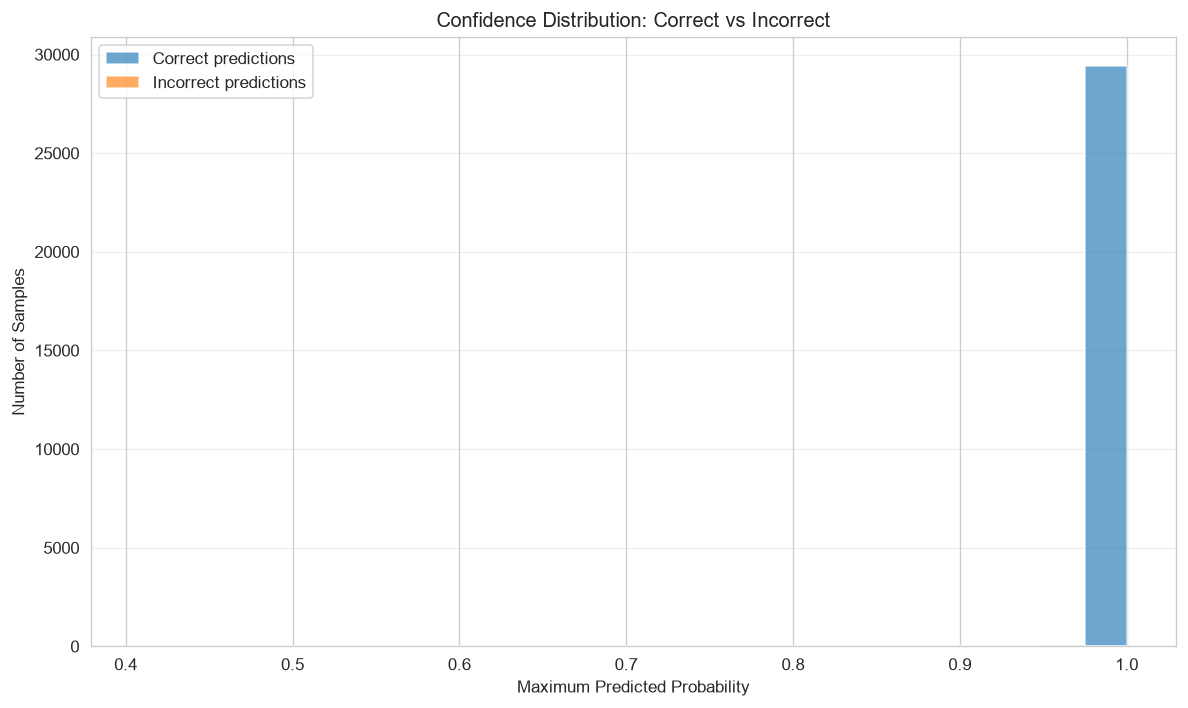


TOP-K ACCURACY
top_1_accuracy           : 0.997542
top_3_accuracy           : 0.999731
top_5_accuracy           : 0.999832

Multiclass mean one-vs-rest Brier score: 0.000136


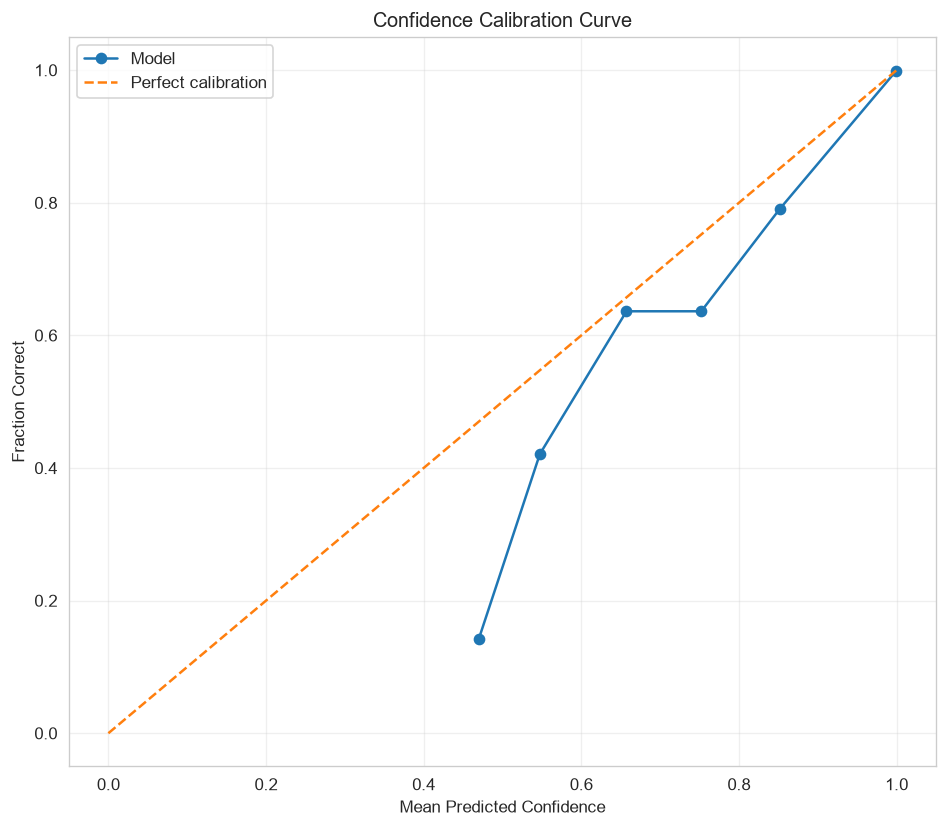


HIGH-CONFIDENCE MISCLASSIFICATIONS
Confidence threshold : 90%
High-confidence errors: 31


,Test_Index,Actual_ID,Predicted_ID,Confidence,Correct,Actual_Class,Predicted_Class
11003,11003,15,16,0.999965,False,normal,pod
2440,2440,15,16,0.999910,False,normal,pod
19388,19388,15,8,0.999469,False,normal,land
4826,4826,15,16,0.999257,False,normal,pod
22373,22373,12,27,0.999206,False,multihop,warezmaster
19831,19831,15,19,0.998788,False,normal,rootkit
19247,19247,3,15,0.998697,False,ftp_write,normal
5102,5102,12,27,0.997324,False,multihop,warezmaster
14233,14233,15,8,0.996912,False,normal,land
5696,5696,15,8,0.996884,False,normal,land



STEP 7.7 COMPLETED SUCCESSFULLY
Results saved in: D:\smart-cybersecurity-ml\results\phase7


In [9]:

# ============================================================
# PHASE 7 — STEP 7.7: CONFIDENCE, CALIBRATION & RISK ANALYSIS
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    top_k_accuracy_score,
    brier_score_loss
)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize

# ------------------------------------------------------------
# 1. Prepare aligned class probabilities
# ------------------------------------------------------------

class_ids = np.asarray(sorted(xgb_model.classes_.tolist()))
probabilities = np.asarray(y_proba_aligned)

if probabilities.shape != (len(y_test), len(class_ids)):
    raise ValueError("Probability matrix has an unexpected shape.")

predicted_confidence = probabilities.max(axis=1)
correct_mask = (y_test == y_pred)
incorrect_mask = ~correct_mask

# ------------------------------------------------------------
# 2. Confidence on correct vs incorrect predictions
# ------------------------------------------------------------

correct_confidence = predicted_confidence[correct_mask]
incorrect_confidence = predicted_confidence[incorrect_mask]

mean_correct_confidence = (
    float(correct_confidence.mean())
    if len(correct_confidence) else None
)

mean_incorrect_confidence = (
    float(incorrect_confidence.mean())
    if len(incorrect_confidence) else None
)

confidence_summary = pd.DataFrame({
    "Prediction_Group": ["Correct", "Incorrect"],
    "Count": [len(correct_confidence), len(incorrect_confidence)],
    "Mean_Confidence": [
        mean_correct_confidence,
        mean_incorrect_confidence
    ]
})

print("=" * 75)
print("PHASE 7 — PREDICTION CONFIDENCE")
print("=" * 75)
display(confidence_summary)

# Plot confidence distributions
plt.figure(figsize=(10, 6))

if len(correct_confidence):
    plt.hist(
        correct_confidence,
        bins=20,
        alpha=0.65,
        label="Correct predictions"
    )

if len(incorrect_confidence):
    plt.hist(
        incorrect_confidence,
        bins=20,
        alpha=0.65,
        label="Incorrect predictions"
    )

plt.xlabel("Maximum Predicted Probability")
plt.ylabel("Number of Samples")
plt.title("Confidence Distribution: Correct vs Incorrect")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_confidence_distribution.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 3. Top-1, Top-3 and Top-5 accuracy
# ------------------------------------------------------------

top_k_results = {}

for k in [1, 3, 5]:
    effective_k = min(k, len(class_ids))

    top_k_results[f"top_{effective_k}_accuracy"] = float(
        top_k_accuracy_score(
            y_test,
            probabilities,
            k=effective_k,
            labels=class_ids
        )
    )

print("\n" + "=" * 75)
print("TOP-K ACCURACY")
print("=" * 75)

for metric, value in top_k_results.items():
    print(f"{metric:25s}: {value:.6f}")

# ------------------------------------------------------------
# 4. Multiclass calibration analysis
# ------------------------------------------------------------

# One-vs-rest Brier score averaged across classes.
y_test_bin = label_binarize(y_test, classes=class_ids)

if y_test_bin.shape != probabilities.shape:
    raise ValueError("Binarized labels do not match probability dimensions.")

brier_per_class = [
    brier_score_loss(y_test_bin[:, i], probabilities[:, i])
    for i in range(len(class_ids))
]

multiclass_brier_score = float(np.mean(brier_per_class))

print("\nMulticlass mean one-vs-rest Brier score:",
      f"{multiclass_brier_score:.6f}")

# Calibration of the maximum predicted probability:
# compare confidence with whether the prediction was correct.
fraction_correct, mean_confidence_bins = calibration_curve(
    correct_mask.astype(int),
    predicted_confidence,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 7))

plt.plot(
    mean_confidence_bins,
    fraction_correct,
    marker="o",
    label="Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Confidence")
plt.ylabel("Fraction Correct")
plt.title("Confidence Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_confidence_calibration.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 5. Create a detailed prediction confidence table
# ------------------------------------------------------------

prediction_analysis = pd.DataFrame({
    "Test_Index": np.arange(len(y_test)),
    "Actual_ID": y_test.astype(int),
    "Predicted_ID": y_pred.astype(int),
    "Confidence": predicted_confidence,
    "Correct": correct_mask
})

prediction_analysis["Actual_Class"] = prediction_analysis[
    "Actual_ID"
].map(lambda class_id: class_names[int(class_id)])

prediction_analysis["Predicted_Class"] = prediction_analysis[
    "Predicted_ID"
].map(lambda class_id: class_names[int(class_id)])

# ------------------------------------------------------------
# 6. Identify high-confidence misclassifications
# ------------------------------------------------------------

# This is an investigation threshold, not a validated risk threshold.
confidence_threshold = 0.90

high_confidence_errors = prediction_analysis[
    (~prediction_analysis["Correct"])
    & (prediction_analysis["Confidence"] >= confidence_threshold)
].copy()

high_confidence_errors = high_confidence_errors.sort_values(
    "Confidence",
    ascending=False
)

high_confidence_errors.to_csv(
    RESULTS_DIR / "phase7_high_confidence_misclassifications.csv",
    index=False
)

prediction_analysis.to_csv(
    RESULTS_DIR / "phase7_prediction_confidence_details.csv",
    index=False
)

print("\n" + "=" * 75)
print("HIGH-CONFIDENCE MISCLASSIFICATIONS")
print("=" * 75)
print(f"Confidence threshold : {confidence_threshold:.0%}")
print(f"High-confidence errors: {len(high_confidence_errors):,}")

if not high_confidence_errors.empty:
    display(high_confidence_errors.head(20))
else:
    print("No misclassifications met the selected confidence threshold.")

# ------------------------------------------------------------
# 7. Summarize the results
# ------------------------------------------------------------

confidence_report = {
    "model": type(xgb_model).__name__,
    "test_samples": int(len(y_test)),
    "correct_predictions": int(correct_mask.sum()),
    "incorrect_predictions": int(incorrect_mask.sum()),
    "mean_confidence_correct": mean_correct_confidence,
    "mean_confidence_incorrect": mean_incorrect_confidence,
    "multiclass_mean_ovr_brier_score": multiclass_brier_score,
    "high_confidence_error_threshold": confidence_threshold,
    "high_confidence_error_count": int(len(high_confidence_errors)),
    **top_k_results
}

with open(
    RESULTS_DIR / "phase7_confidence_calibration_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(confidence_report, file, indent=4)

print("\n" + "=" * 75)
print("STEP 7.7 COMPLETED SUCCESSFULLY")
print("=" * 75)
print(f"Results saved in: {RESULTS_DIR}")


Phase 7 — Step 7.8: Support vs F1/Recall Correlation Analysis

PHASE 7 — SUPPORT VS PERFORMANCE ANALYSIS
Classes analyzed: 28


,Metric,Pearson_Support,Spearman_Support,Spearman_Log10_Support
0,Precision,0.1546,0.2406,0.2406
1,Recall,0.1583,0.2350,0.2350
2,F1_Score,0.1646,0.4222,0.4222


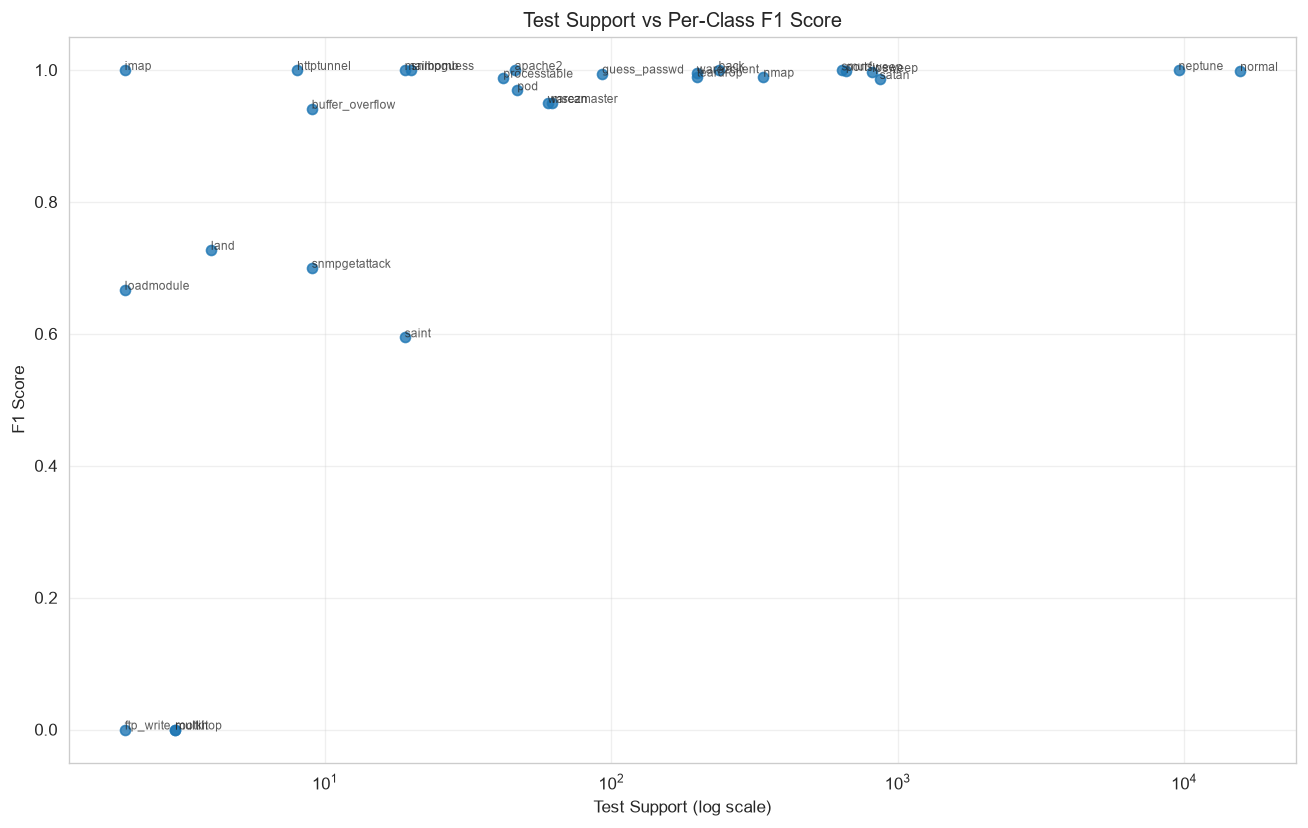

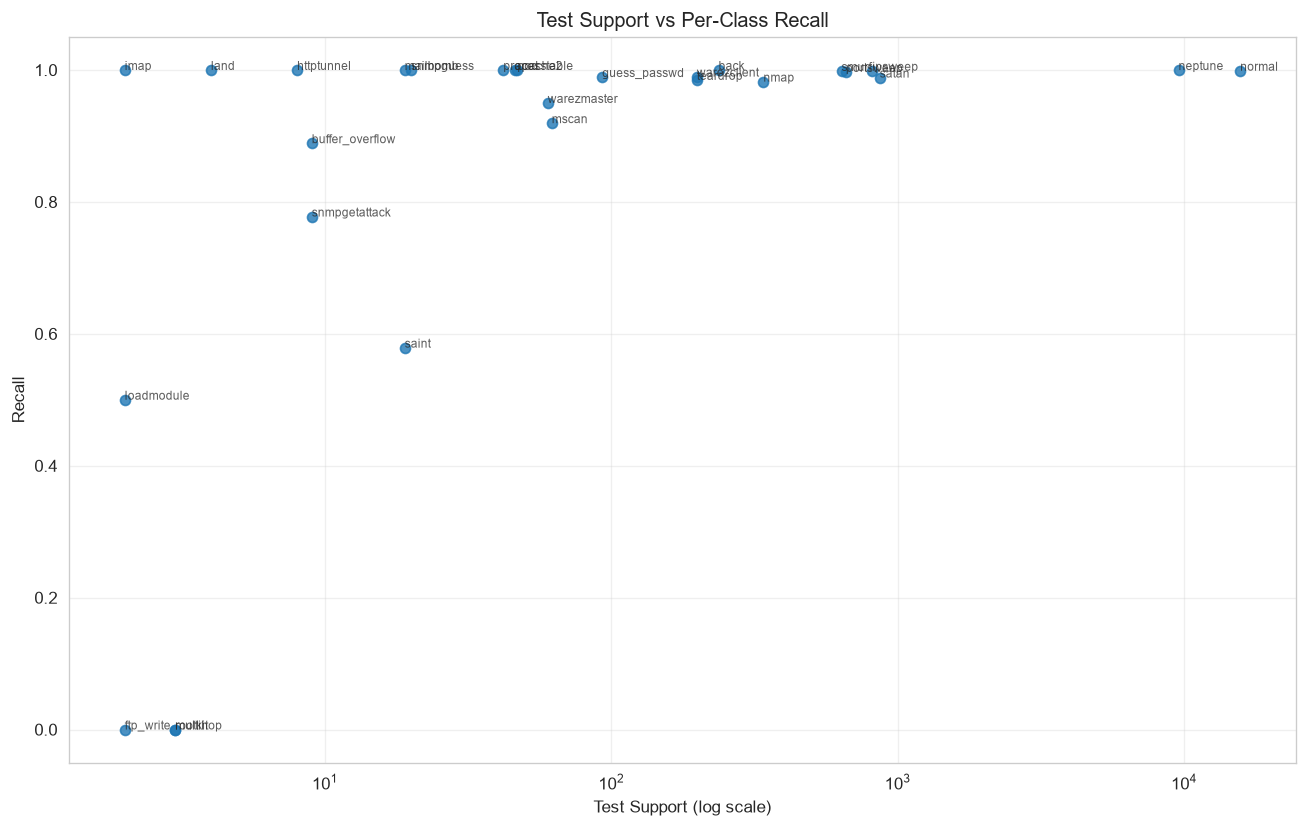


RARE CLASSES WITH WEAK F1
Support threshold: fewer than 100 samples
F1 threshold: below 0.50
Matching classes: 3


,Attack_Class,Support,Precision,Recall,F1_Score
0,ftp_write,2,0.0000,0.0000,0.0000
1,multihop,3,0.0000,0.0000,0.0000
2,rootkit,3,0.0000,0.0000,0.0000



STEP 7.8 COMPLETED SUCCESSFULLY
Results saved in: D:\smart-cybersecurity-ml\results\phase7


In [10]:

# ============================================================
# PHASE 7 — STEP 7.8: SUPPORT VS F1 / RECALL CORRELATION
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Prepare per-class metrics
# ------------------------------------------------------------

correlation_df = per_class_df[
    ["Attack_Class", "Precision", "Recall", "F1_Score", "Support"]
].copy()

correlation_df = correlation_df.replace(
    [np.inf, -np.inf],
    np.nan
).dropna(
    subset=["Precision", "Recall", "F1_Score", "Support"]
)

correlation_df["Support"] = correlation_df["Support"].astype(int)

# Log scale helps visualize differences between rare and common classes.
correlation_df["Log10_Support"] = np.log10(
    correlation_df["Support"].clip(lower=1)
)

correlation_df.to_csv(
    RESULTS_DIR / "phase7_support_performance_analysis.csv",
    index=False
)

print("=" * 75)
print("PHASE 7 — SUPPORT VS PERFORMANCE ANALYSIS")
print("=" * 75)
print(f"Classes analyzed: {len(correlation_df)}")

# ------------------------------------------------------------
# 2. Calculate correlations
# ------------------------------------------------------------

metrics_to_check = ["Precision", "Recall", "F1_Score"]

correlation_results = []

for metric in metrics_to_check:
    # Pearson: linear relationship.
    pearson_value = correlation_df["Support"].corr(
        correlation_df[metric],
        method="pearson"
    )

    # Spearman: monotonic relationship; useful for skewed support.
    spearman_value = correlation_df["Support"].corr(
        correlation_df[metric],
        method="spearman"
    )

    # Repeat using log-transformed support.
    log_spearman_value = correlation_df["Log10_Support"].corr(
        correlation_df[metric],
        method="spearman"
    )

    correlation_results.append({
        "Metric": metric,
        "Pearson_Support": pearson_value,
        "Spearman_Support": spearman_value,
        "Spearman_Log10_Support": log_spearman_value
    })

correlation_results_df = pd.DataFrame(correlation_results)

correlation_results_df.to_csv(
    RESULTS_DIR / "phase7_support_performance_correlations.csv",
    index=False
)

display(
    correlation_results_df.style.format({
        "Pearson_Support": "{:.4f}",
        "Spearman_Support": "{:.4f}",
        "Spearman_Log10_Support": "{:.4f}"
    }, na_rep="N/A")
)

# ------------------------------------------------------------
# 3. Plot support vs F1 score
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

plt.scatter(
    correlation_df["Support"],
    correlation_df["F1_Score"],
    alpha=0.8
)

for _, row in correlation_df.iterrows():
    plt.annotate(
        row["Attack_Class"],
        (row["Support"], row["F1_Score"]),
        fontsize=7,
        alpha=0.75
    )

plt.xscale("log")
plt.xlabel("Test Support (log scale)")
plt.ylabel("F1 Score")
plt.title("Test Support vs Per-Class F1 Score")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_support_vs_f1.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 4. Plot support vs recall
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

plt.scatter(
    correlation_df["Support"],
    correlation_df["Recall"],
    alpha=0.8
)

for _, row in correlation_df.iterrows():
    plt.annotate(
        row["Attack_Class"],
        (row["Support"], row["Recall"]),
        fontsize=7,
        alpha=0.75
    )

plt.xscale("log")
plt.xlabel("Test Support (log scale)")
plt.ylabel("Recall")
plt.title("Test Support vs Per-Class Recall")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "phase7_support_vs_recall.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 5. Identify rare classes with weak F1
# ------------------------------------------------------------

# These thresholds are for investigation, not universal standards.
rare_support_threshold = 100
weak_f1_threshold = 0.50

rare_weak_classes = correlation_df[
    (correlation_df["Support"] < rare_support_threshold)
    & (correlation_df["F1_Score"] < weak_f1_threshold)
].sort_values(
    ["F1_Score", "Support"],
    ascending=[True, True]
)

rare_weak_classes.to_csv(
    RESULTS_DIR / "phase7_rare_weak_classes.csv",
    index=False
)

print("\n" + "=" * 75)
print("RARE CLASSES WITH WEAK F1")
print("=" * 75)
print(f"Support threshold: fewer than {rare_support_threshold} samples")
print(f"F1 threshold: below {weak_f1_threshold:.2f}")
print(f"Matching classes: {len(rare_weak_classes)}")

if not rare_weak_classes.empty:
    display(
        rare_weak_classes[
            ["Attack_Class", "Support", "Precision", "Recall", "F1_Score"]
        ].style.format({
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1_Score": "{:.4f}",
            "Support": "{:,}"
        })
    )
else:
    print("No classes met both selected thresholds.")

# ------------------------------------------------------------
# 6. Save a machine-readable summary
# ------------------------------------------------------------

summary = {
    "classes_analyzed": int(len(correlation_df)),
    "rare_support_threshold": rare_support_threshold,
    "weak_f1_threshold": weak_f1_threshold,
    "rare_weak_class_count": int(len(rare_weak_classes)),
    "correlations": [
        {
            key: (
                None if pd.isna(value)
                else float(value) if isinstance(value, (float, np.floating))
                else value
            )
            for key, value in row.items()
        }
        for row in correlation_results_df.to_dict(orient="records")
    ]
}

with open(
    RESULTS_DIR / "phase7_support_correlation_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(summary, file, indent=4)

print("\n" + "=" * 75)
print("STEP 7.8 COMPLETED SUCCESSFULLY")
print("=" * 75)
print(f"Results saved in: {RESULTS_DIR}")


Phase 7 — Step 7.9: Evaluation Dashboard

PHASE 7 — XGBOOST DEEP MODEL EVALUATION DASHBOARD
Model                 : XGBClassifier
Test samples          : 29,696
Number of classes     : 28
Accuracy              : 0.9975
Balanced accuracy     : 0.8408
Macro F1              : 0.8370
Weighted F1           : 0.9974
Macro precision       : 0.8442
Macro recall          : 0.8408
Matthews correlation  : 0.9960
Log loss              : 0.0099
Top-3 accuracy        : 0.9997


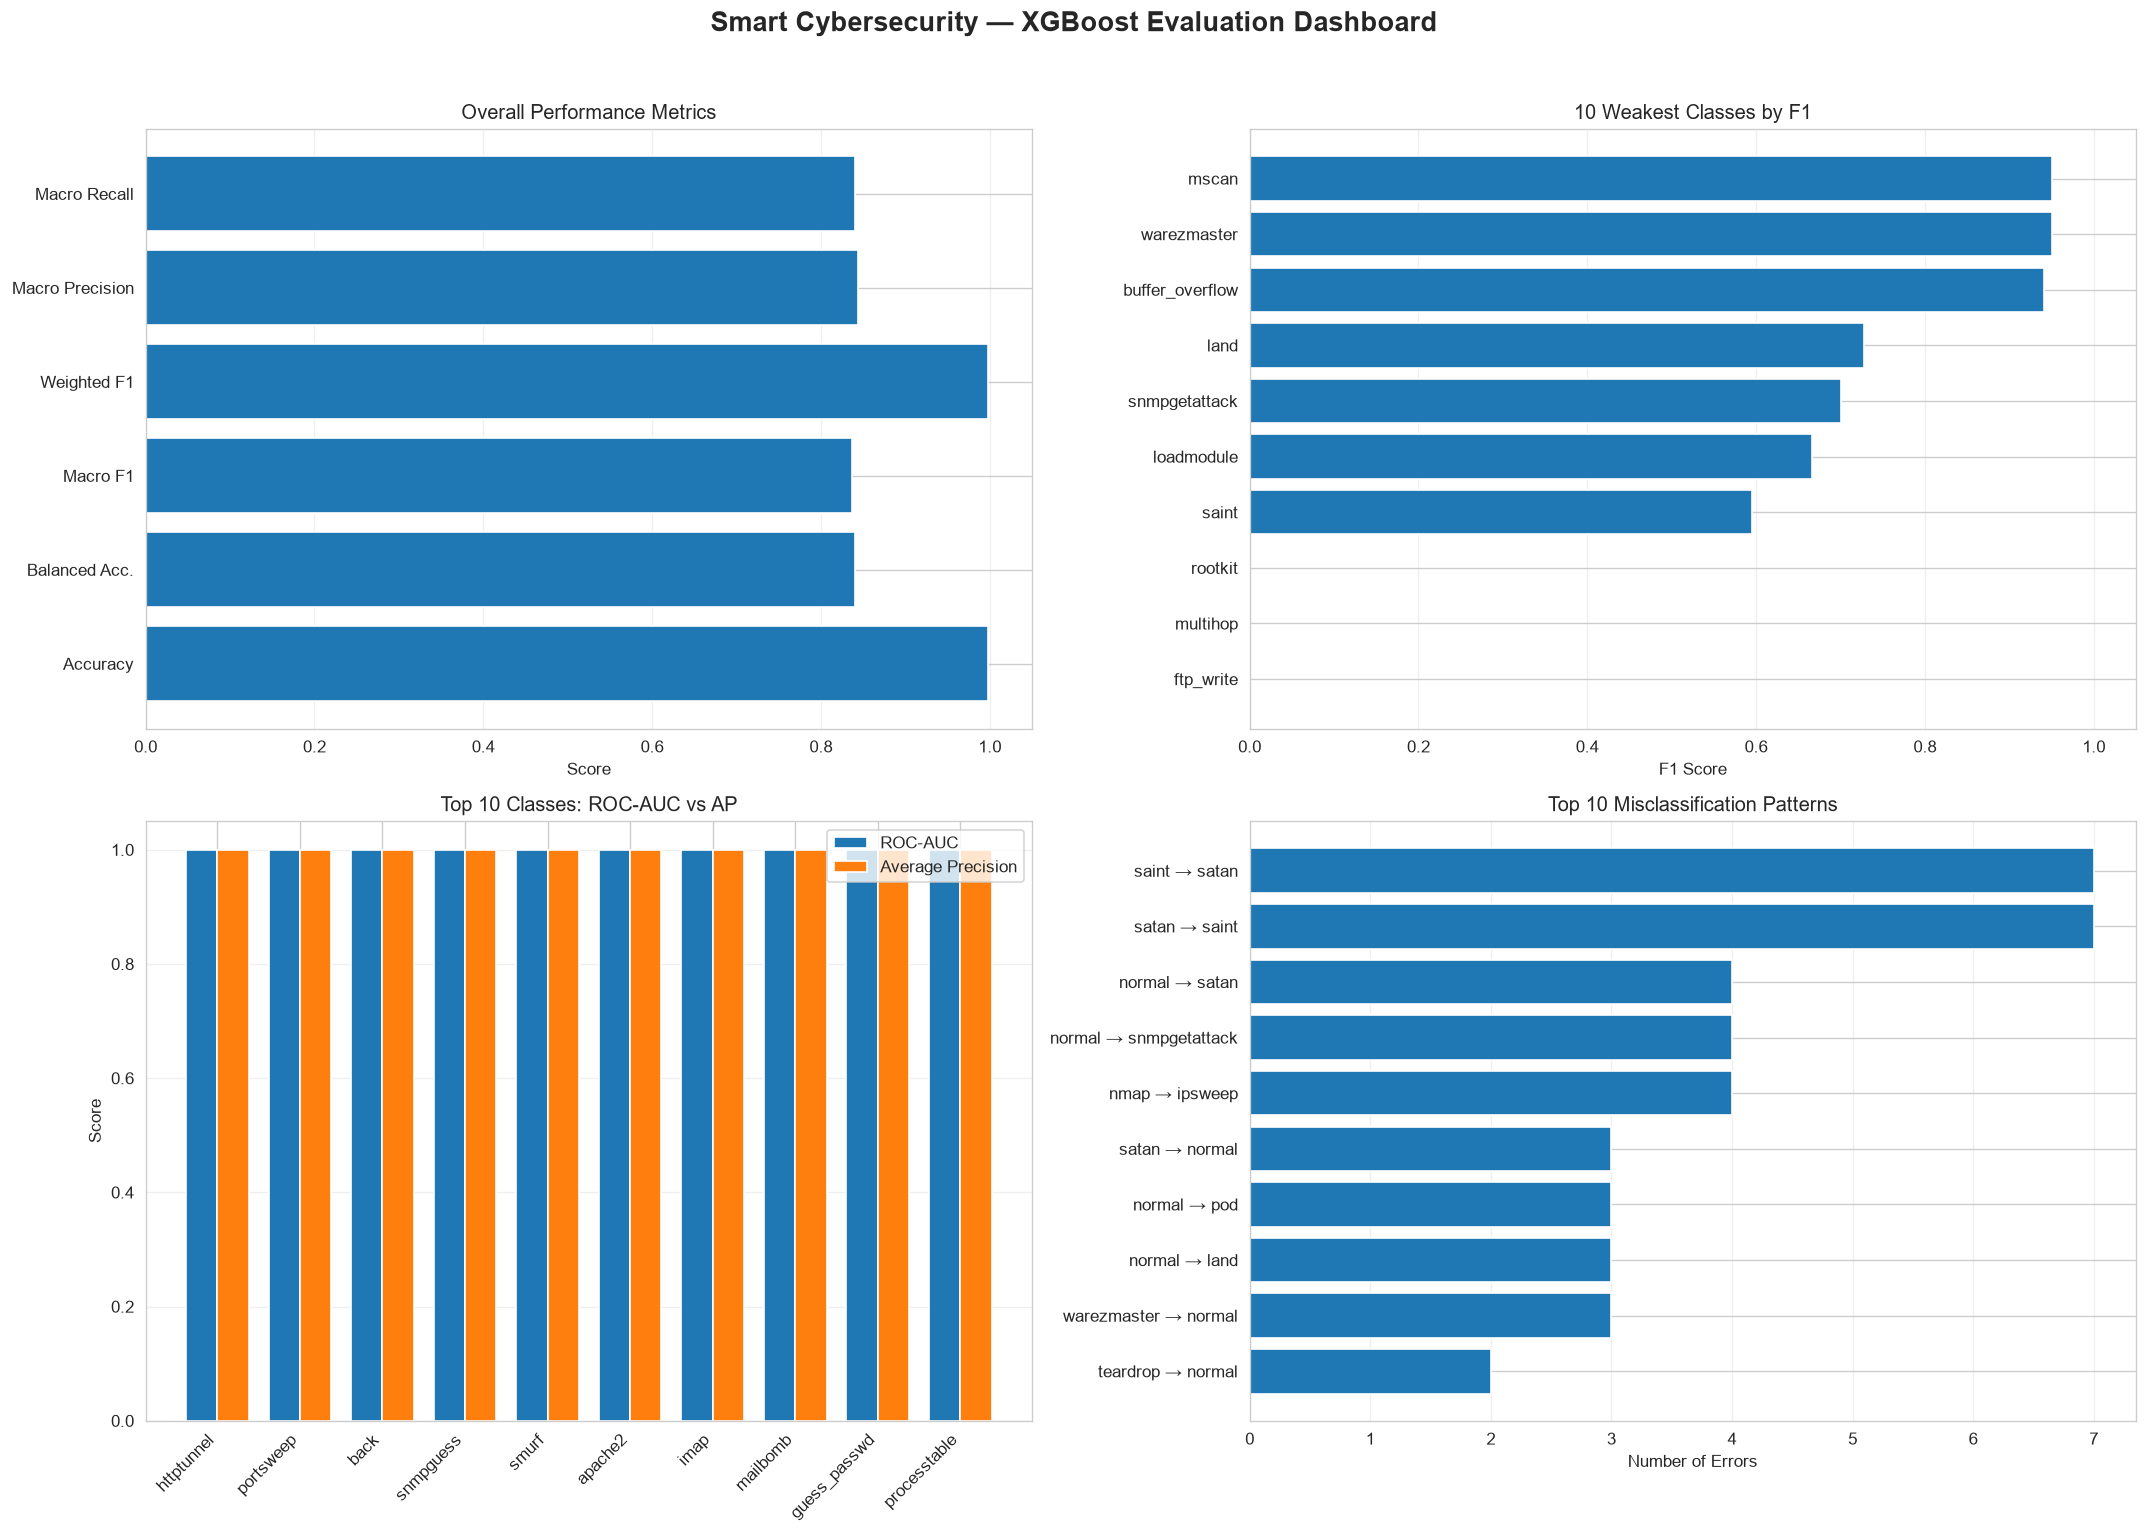


STEP 7.9 COMPLETED SUCCESSFULLY
Dashboard image: D:\smart-cybersecurity-ml\results\phase7\phase7_evaluation_dashboard.png
Dashboard data : D:\smart-cybersecurity-ml\results\phase7\phase7_dashboard_class_metrics.csv
Dashboard summary: D:\smart-cybersecurity-ml\results\phase7\phase7_dashboard_summary.json


In [11]:

# ============================================================
# PHASE 7 — STEP 7.9: MODEL EVALUATION DASHBOARD
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Prepare dashboard data
# ------------------------------------------------------------

# Load the saved overall metrics from Step 7.2
with open(
    RESULTS_DIR / "phase7_overall_metrics.json",
    "r",
    encoding="utf-8"
) as file:
    overall_data = json.load(file)

overall_metrics = overall_data["metrics"]

# Per-class F1 results from Step 7.6
dashboard_classes = class_performance.copy()

# ROC-AUC results from Step 7.4
roc_dashboard = pd.read_csv(
    RESULTS_DIR / "phase7_roc_auc_per_class.csv"
)

# Average Precision results from Step 7.5
pr_dashboard = pd.read_csv(
    RESULTS_DIR / "phase7_precision_recall_per_class.csv"
)

# Misclassification patterns from Step 7.3
error_dashboard = pd.read_csv(
    RESULTS_DIR / "phase7_misclassification_patterns.csv"
)

# ------------------------------------------------------------
# 2. Merge class-level metrics
# ------------------------------------------------------------

dashboard_df = dashboard_classes[
    ["Class_ID", "Attack_Class", "Precision", "Recall", "F1_Score", "Support"]
].copy()

dashboard_df = dashboard_df.merge(
    roc_dashboard[["Class_ID", "AUC"]],
    on="Class_ID",
    how="left"
)

dashboard_df = dashboard_df.merge(
    pr_dashboard[["Class_ID", "Average_Precision"]],
    on="Class_ID",
    how="left"
)

dashboard_df.to_csv(
    RESULTS_DIR / "phase7_dashboard_class_metrics.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Print dashboard summary
# ------------------------------------------------------------

print("=" * 85)
print("PHASE 7 — XGBOOST DEEP MODEL EVALUATION DASHBOARD")
print("=" * 85)

print(f"Model                 : {overall_data.get('model', 'XGBoost')}")
print(f"Test samples          : {overall_metrics['test_samples']:,}")
print(f"Number of classes     : {overall_metrics['number_of_classes']}")
print(f"Accuracy              : {overall_metrics['accuracy']:.4f}")
print(f"Balanced accuracy     : {overall_metrics['balanced_accuracy']:.4f}")
print(f"Macro F1              : {overall_metrics['macro_f1']:.4f}")
print(f"Weighted F1           : {overall_metrics['weighted_f1']:.4f}")
print(f"Macro precision       : {overall_metrics['macro_precision']:.4f}")
print(f"Macro recall          : {overall_metrics['macro_recall']:.4f}")
print(f"Matthews correlation  : {overall_metrics['matthews_corrcoef']:.4f}")
print(f"Log loss              : {overall_metrics['log_loss']:.4f}")
print(f"Top-3 accuracy        : {overall_metrics['top_3_accuracy']:.4f}")

# ------------------------------------------------------------
# 4. Build a dashboard with four panels
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(18, 13))

# Panel A: Overall metric comparison
metric_names = [
    "Accuracy",
    "Balanced Acc.",
    "Macro F1",
    "Weighted F1",
    "Macro Precision",
    "Macro Recall"
]

metric_keys = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "weighted_f1",
    "macro_precision",
    "macro_recall"
]

metric_values = [
    overall_metrics[key]
    for key in metric_keys
]

axes[0, 0].barh(metric_names, metric_values)
axes[0, 0].set_xlim(0, 1.05)
axes[0, 0].set_title("Overall Performance Metrics")
axes[0, 0].set_xlabel("Score")
axes[0, 0].grid(axis="x", alpha=0.3)

# Panel B: Lowest 10 F1 classes
weakest = dashboard_df.sort_values(
    "F1_Score",
    ascending=True
).head(10)

axes[0, 1].barh(
    weakest["Attack_Class"],
    weakest["F1_Score"]
)

axes[0, 1].set_xlim(0, 1.05)
axes[0, 1].set_title("10 Weakest Classes by F1")
axes[0, 1].set_xlabel("F1 Score")
axes[0, 1].grid(axis="x", alpha=0.3)

# Panel C: Per-class ROC-AUC and AP
valid_auc_ap = dashboard_df.dropna(
    subset=["AUC", "Average_Precision"]
).copy()

if not valid_auc_ap.empty:
    strongest_auc_ap = valid_auc_ap.sort_values(
        "AUC",
        ascending=False
    ).head(10)

    positions = np.arange(len(strongest_auc_ap))
    width = 0.38

    axes[1, 0].bar(
        positions - width / 2,
        strongest_auc_ap["AUC"],
        width,
        label="ROC-AUC"
    )

    axes[1, 0].bar(
        positions + width / 2,
        strongest_auc_ap["Average_Precision"],
        width,
        label="Average Precision"
    )

    axes[1, 0].set_xticks(positions)
    axes[1, 0].set_xticklabels(
        strongest_auc_ap["Attack_Class"],
        rotation=45,
        ha="right"
    )

    axes[1, 0].set_ylim(0, 1.05)
    axes[1, 0].set_title("Top 10 Classes: ROC-AUC vs AP")
    axes[1, 0].set_ylabel("Score")
    axes[1, 0].legend()
    axes[1, 0].grid(axis="y", alpha=0.3)
else:
    axes[1, 0].text(
        0.5, 0.5,
        "No valid ROC-AUC/AP values available",
        ha="center",
        va="center"
    )
    axes[1, 0].set_title("ROC-AUC vs Average Precision")

# Panel D: Most frequent classification errors
if not error_dashboard.empty:
    top_errors = error_dashboard.sort_values(
        "Error_Count",
        ascending=False
    ).head(10).copy()

    top_errors["Error_Label"] = (
        top_errors["Actual_Class"]
        + " → "
        + top_errors["Predicted_Class"]
    )

    axes[1, 1].barh(
        top_errors["Error_Label"].iloc[::-1],
        top_errors["Error_Count"].iloc[::-1]
    )

    axes[1, 1].set_title("Top 10 Misclassification Patterns")
    axes[1, 1].set_xlabel("Number of Errors")
    axes[1, 1].grid(axis="x", alpha=0.3)
else:
    axes[1, 1].text(
        0.5, 0.5,
        "No misclassification patterns found",
        ha="center",
        va="center"
    )
    axes[1, 1].set_title("Misclassification Patterns")

fig.suptitle(
    "Smart Cybersecurity — XGBoost Evaluation Dashboard",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    RESULTS_DIR / "phase7_evaluation_dashboard.png",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Save dashboard summary
# ------------------------------------------------------------

dashboard_summary = {
    "model": overall_data.get("model", "XGBoost"),
    "test_samples": overall_metrics["test_samples"],
    "number_of_classes": overall_metrics["number_of_classes"],
    "accuracy": overall_metrics["accuracy"],
    "balanced_accuracy": overall_metrics["balanced_accuracy"],
    "macro_f1": overall_metrics["macro_f1"],
    "weighted_f1": overall_metrics["weighted_f1"],
    "weakest_classes": weakest[
        ["Attack_Class", "F1_Score", "Support"]
    ].to_dict(orient="records"),
    "top_error_patterns": error_dashboard.sort_values(
        "Error_Count",
        ascending=False
    ).head(10).to_dict(orient="records")
}

with open(
    RESULTS_DIR / "phase7_dashboard_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(dashboard_summary, file, indent=4)

print("\n" + "=" * 85)
print("STEP 7.9 COMPLETED SUCCESSFULLY")
print("=" * 85)
print(f"Dashboard image: {RESULTS_DIR / 'phase7_evaluation_dashboard.png'}")
print(f"Dashboard data : {RESULTS_DIR / 'phase7_dashboard_class_metrics.csv'}")
print(f"Dashboard summary: {RESULTS_DIR / 'phase7_dashboard_summary.json'}")


Phase 7 — Step 7.10: Automatically Generate the Final Evaluation Report

In [12]:

# ============================================================
# PHASE 7 — STEP 7.10: AUTOMATED EVALUATION REPORT
# ============================================================

import json
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# 1. Load saved evaluation results
# ------------------------------------------------------------

with open(
    RESULTS_DIR / "phase7_overall_metrics.json",
    "r",
    encoding="utf-8"
) as file:
    overall_data = json.load(file)

metrics = overall_data["metrics"]

class_metrics = pd.read_csv(
    RESULTS_DIR / "phase7_dashboard_class_metrics.csv"
)

support_analysis = pd.read_csv(
    RESULTS_DIR / "phase7_support_performance_analysis.csv"
)

confidence_details = pd.read_csv(
    RESULTS_DIR / "phase7_prediction_confidence_details.csv"
)

high_confidence_errors = pd.read_csv(
    RESULTS_DIR / "phase7_high_confidence_misclassifications.csv"
)

error_patterns = pd.read_csv(
    RESULTS_DIR / "phase7_misclassification_patterns.csv"
)

# ------------------------------------------------------------
# 2. Calculate report summaries
# ------------------------------------------------------------

weakest_classes = class_metrics.sort_values(
    "F1_Score",
    ascending=True
).head(10)

best_classes = class_metrics.sort_values(
    "F1_Score",
    ascending=False
).head(10)

rare_weak_classes = support_analysis[
    (support_analysis["Support"] < 100)
    & (support_analysis["F1_Score"] < 0.50)
].sort_values("F1_Score")

correct_predictions = int(
    (confidence_details["Correct"] == True).sum()
)

incorrect_predictions = int(
    (confidence_details["Correct"] == False).sum()
)

total_predictions = len(confidence_details)

accuracy_check = (
    correct_predictions / total_predictions
    if total_predictions > 0
    else 0
)

# ------------------------------------------------------------
# 3. Build report content
# ------------------------------------------------------------

report = []

report.append("# Phase 7 — Deep Model Evaluation Report")
report.append("")
report.append(f"**Generated:** {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
report.append("")
report.append("## 1. Project Overview")
report.append("")
report.append(
    "This report evaluates the trained XGBoost intrusion-detection "
    "model using overall classification metrics, per-class performance, "
    "ranking metrics, confidence analysis, and misclassification analysis."
)
report.append("")
report.append("## 2. Overall Performance")
report.append("")
report.append("| Metric | Value |")
report.append("|---|---:|")

metric_labels = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "macro_precision": "Macro Precision",
    "macro_recall": "Macro Recall",
    "macro_f1": "Macro F1",
    "weighted_f1": "Weighted F1",
    "matthews_corrcoef": "Matthews Correlation Coefficient",
    "log_loss": "Log Loss",
    "top_3_accuracy": "Top-3 Accuracy",
}

for key, label in metric_labels.items():
    if key in metrics:
        report.append(f"| {label} | {metrics[key]:.6f} |")

report.append("")
report.append(f"- **Test samples:** {metrics.get('test_samples', total_predictions):,}")
report.append(
    f"- **Number of classes:** "
    f"{metrics.get('number_of_classes', class_metrics['Attack_Class'].nunique())}"
)
report.append("")
report.append("## 3. Strongest Classes")
report.append("")
report.append("| Class | Precision | Recall | F1 Score | Support |")
report.append("|---|---:|---:|---:|---:|")

for _, row in best_classes.iterrows():
    report.append(
        f"| {row['Attack_Class']} | "
        f"{row['Precision']:.4f} | "
        f"{row['Recall']:.4f} | "
        f"{row['F1_Score']:.4f} | "
        f"{int(row['Support'])} |"
    )

report.append("")
report.append("## 4. Weakest Classes")
report.append("")
report.append("| Class | Precision | Recall | F1 Score | Support |")
report.append("|---|---:|---:|---:|---:|")

for _, row in weakest_classes.iterrows():
    report.append(
        f"| {row['Attack_Class']} | "
        f"{row['Precision']:.4f} | "
        f"{row['Recall']:.4f} | "
        f"{row['F1_Score']:.4f} | "
        f"{int(row['Support'])} |"
    )

report.append("")
report.append("## 5. Rare Classes with Weak F1")
report.append("")
report.append(
    "The following classes have fewer than 100 test samples and an F1 "
    "score below 0.50. These thresholds are used for investigation, "
    "not as universal definitions of poor performance."
)
report.append("")

if rare_weak_classes.empty:
    report.append("No classes met both selected thresholds.")
else:
    report.append("| Class | F1 Score | Support | Recall |")
    report.append("|---|---:|---:|---:|")

    for _, row in rare_weak_classes.iterrows():
        report.append(
            f"| {row['Attack_Class']} | "
            f"{row['F1_Score']:.4f} | "
            f"{int(row['Support'])} | "
            f"{row['Recall']:.4f} |"
        )

report.append("")
report.append("## 6. Prediction and Confidence Analysis")
report.append("")
report.append(f"- Correct predictions: **{correct_predictions:,}**")
report.append(f"- Incorrect predictions: **{incorrect_predictions:,}**")
report.append(f"- Total predictions analyzed: **{total_predictions:,}**")
report.append(f"- Accuracy recalculated from prediction details: **{accuracy_check:.6f}**")
report.append(
    f"- High-confidence incorrect predictions: **{len(high_confidence_errors):,}**"
)
report.append("")
report.append(
    "High-confidence errors deserve review because the model assigned "
    "high confidence to an incorrect prediction. Confidence alone does "
    "not establish whether an intrusion was successfully prevented."
)
report.append("")
report.append("## 7. Frequent Misclassification Patterns")
report.append("")

if error_patterns.empty:
    report.append("No misclassification patterns were recorded.")
else:
    report.append("| Actual Class | Predicted Class | Error Count |")
    report.append("|---|---|---:|")

    top_errors = error_patterns.sort_values(
        "Error_Count",
        ascending=False
    ).head(10)

    for _, row in top_errors.iterrows():
        report.append(
            f"| {row['Actual_Class']} | "
            f"{row['Predicted_Class']} | "
            f"{int(row['Error_Count'])} |"
        )

report.append("")
report.append("## 8. ROC-AUC and Average Precision")
report.append("")
report.append(
    "Refer to `phase7_roc_auc_summary.json`, "
    "`phase7_precision_recall_summary.json`, and the dashboard class-metrics "
    "CSV for the detailed ranking metrics. These metrics can help assess "
    "how well classes are separated or ranked, but do not replace "
    "precision, recall, and F1."
)
report.append("")
report.append("## 9. Evaluation Dashboard")
report.append("")
report.append(
    "The visual summary is saved as "
    "`results/phase7/phase7_evaluation_dashboard.png`."
)
report.append("")
report.append("## 10. Limitations and Next Steps")
report.append("")
report.append(
    "- Evaluate weak and rare classes individually; overall accuracy can "
    "hide poor minority-class performance."
)
report.append(
    "- Investigate high-confidence errors and the most frequent "
    "actual-to-predicted class confusions."
)
report.append(
    "- Validate on appropriately separated, representative data before "
    "making deployment claims."
)
report.append(
    "- A classification result is not proof that a threat was blocked. "
    "Prevention requires an integrated response mechanism and separate "
    "testing of its actions."
)
report.append("")
report.append("## 11. Conclusion")
report.append("")
report.append(
    f"The evaluated model achieved an accuracy of {metrics['accuracy']:.4f}, "
    f"macro F1 of {metrics['macro_f1']:.4f}, and weighted F1 of "
    f"{metrics['weighted_f1']:.4f} on the evaluated test set. "
    "Per-class results and error analysis should be considered alongside "
    "these overall metrics when assessing intrusion-detection performance."
)
report.append("")

# ------------------------------------------------------------
# 4. Save the Markdown report
# ------------------------------------------------------------

report_path = REPORTS_DIR / "phase7_final_evaluation_report.md"

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:
    file.write("\n".join(report))

print("=" * 75)
print("STEP 7.10 COMPLETED SUCCESSFULLY")
print("=" * 75)
print(f"Report saved to: {report_path}")
print(f"Report sections generated: {sum(line.startswith('## ') for line in report)}")
print(f"Report size: {report_path.stat().st_size:,} bytes")


STEP 7.10 COMPLETED SUCCESSFULLY
Report saved to: D:\smart-cybersecurity-ml\reports\phase7\phase7_final_evaluation_report.md
Report sections generated: 11
Report size: 4,265 bytes


Phase 7 — Step 7.11: Final Summary and Completion Checklist

In [14]:

# ============================================================
# PHASE 7 — STEP 7.11: FINAL SUMMARY AND COMPLETION CHECKLIST
# ============================================================

import json
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. Load final evaluation metrics
# ------------------------------------------------------------

with open(
    RESULTS_DIR / "phase7_overall_metrics.json",
    "r",
    encoding="utf-8"
) as file:
    final_data = json.load(file)

final_metrics = final_data["metrics"]

# ------------------------------------------------------------
# 2. Define expected output files
# ------------------------------------------------------------

expected_files = {
    "Overall metrics": (
        RESULTS_DIR / "phase7_overall_metrics.json"
    ),
    "Per-class metrics": (
        RESULTS_DIR / "phase7_per_class_metrics.csv"
    ),
    "Classification report": (
        REPORTS_DIR / "phase7_classification_report.txt"
    ),
    "Confusion matrix": (
        RESULTS_DIR / "phase7_confusion_matrix.png"
    ),
    "ROC-AUC summary": (
        RESULTS_DIR / "phase7_roc_auc_summary.json"
    ),
    "Precision-recall summary": (
        RESULTS_DIR / "phase7_precision_recall_summary.json"
    ),
    "Confidence analysis": (
        RESULTS_DIR / "phase7_confidence_calibration_summary.json"
    ),
    "Support-performance analysis": (
        RESULTS_DIR / "phase7_support_correlation_summary.json"
    ),
    "Evaluation dashboard": (
        RESULTS_DIR / "phase7_evaluation_dashboard.png"
    ),
    "Dashboard class metrics": (
        RESULTS_DIR / "phase7_dashboard_class_metrics.csv"
    ),
    "Final evaluation report": (
        REPORTS_DIR / "phase7_final_evaluation_report.md"
    ),
}

# ------------------------------------------------------------
# 3. Check generated files
# ------------------------------------------------------------

checklist = []

for name, path in expected_files.items():
    exists = path.exists()

    checklist.append({
        "Output": name,
        "Status": "PASS" if exists else "MISSING",
        "Path": str(path)
    })

checklist_df = pd.DataFrame(checklist)

print("=" * 85)
print("PHASE 7 — FINAL COMPLETION CHECKLIST")
print("=" * 85)

display(checklist_df)

checklist_df.to_csv(
    RESULTS_DIR / "phase7_completion_checklist.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Display final model results
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("FINAL XGBOOST EVALUATION RESULTS")
print("=" * 85)

print(f"Test samples       : {final_metrics['test_samples']:,}")
print(f"Number of classes  : {final_metrics['number_of_classes']}")
print(f"Accuracy           : {final_metrics['accuracy']:.6f}")
print(f"Balanced accuracy  : {final_metrics['balanced_accuracy']:.6f}")
print(f"Macro F1           : {final_metrics['macro_f1']:.6f}")
print(f"Weighted F1        : {final_metrics['weighted_f1']:.6f}")
print(f"Macro precision    : {final_metrics['macro_precision']:.6f}")
print(f"Macro recall       : {final_metrics['macro_recall']:.6f}")

# ------------------------------------------------------------
# 5. Calculate completion status
# ------------------------------------------------------------

passed = sum(
    item["Status"] == "PASS"
    for item in checklist
)

total = len(checklist)
missing = total - passed

print("\n" + "=" * 85)
print("PHASE 7 SUMMARY")
print("=" * 85)

print(f"Expected outputs : {total}")
print(f"Existing outputs : {passed}")
print(f"Missing outputs  : {missing}")

if missing == 0:
    print("\nAll expected Phase 7 outputs exist.")
else:
    print("\nSome expected outputs are missing.")
    print("Review the MISSING entries in the checklist.")

print("\nChecklist saved to:")
print(RESULTS_DIR / "phase7_completion_checklist.csv")

print("\nSTEP 7.11 COMPLETED")


PHASE 7 — FINAL COMPLETION CHECKLIST


,Output,Status,Path
0,Overall metrics,PASS,D:\smart-cybersecurity-ml\results\phase7\phase...
1,Per-class metrics,PASS,D:\smart-cybersecurity-ml\results\phase7\phase...
2,Classification report,PASS,D:\smart-cybersecurity-ml\reports\phase7\phase...
3,Confusion matrix,MISSING,D:\smart-cybersecurity-ml\results\phase7\phase...
4,ROC-AUC summary,MISSING,D:\smart-cybersecurity-ml\results\phase7\phase...
5,Precision-recall summary,MISSING,D:\smart-cybersecurity-ml\results\phase7\phase...
6,Confidence analysis,PASS,D:\smart-cybersecurity-ml\results\phase7\phase...
7,Support-performance analysis,PASS,D:\smart-cybersecurity-ml\results\phase7\phase...
8,Evaluation dashboard,PASS,D:\smart-cybersecurity-ml\results\phase7\phase...
9,Dashboard class metrics,PASS,D:\smart-cybersecurity-ml\results\phase7\phase...



FINAL XGBOOST EVALUATION RESULTS
Test samples       : 29,696
Number of classes  : 28
Accuracy           : 0.997542
Balanced accuracy  : 0.840815
Macro F1           : 0.836976
Weighted F1        : 0.997449
Macro precision    : 0.844194
Macro recall       : 0.840815

PHASE 7 SUMMARY
Expected outputs : 11
Existing outputs : 8
Missing outputs  : 3

Some expected outputs are missing.
Review the MISSING entries in the checklist.

Checklist saved to:
D:\smart-cybersecurity-ml\results\phase7\phase7_completion_checklist.csv

STEP 7.11 COMPLETED
